# W2 · From exploratory analysis to credible validation
## How strongly is the starting position associated with the final result in Formula 1? (2014–2024)
**Business Intelligence · IIB423T-1 · Universidad del Desarrollo** — **Group 06** — Maximiliano Sandoval and Benjamín Toloza ·
Instructor: Tomás Fontecilla Correa · Workshop 2 · October 2026

**Purpose.** This notebook continues the W1/C1 project (same question, user, KPI and unit of observation). It (1) answers the
instructor's feedback on C1, (2) repairs the exploratory evidence, (3) validates the cleaned data with executable checks,
(4) assesses sampling and representativeness, (5) audits leakage and (6) builds a train/validation/test design for the
future predictive use proposed in C1. **No model is fitted and no performance metric is reported**, as W2 requires.

**How to read it.** Text blocks are labelled **Observation** (what the output shows), **Assumption** (what we take as given and
could be wrong) and **Managerial recommendation** (what we would tell the user). Every number quoted in the text is printed by
the code cell just above it.

**Run order.** `analysis/01` → `analysis/02` (writes the analytic table) → `analysis/03` → **this notebook**. It reads
`data/raw/` and `data/processed/analytic_driver_race_2014_2024.csv`, and writes its outputs to `data/processed/w2_*` and
`analysis/figures/W2_*`. Random operations use the fixed seed `2026`.

| Part | Content | W2 rubric |
|---|---|---|
| 1 | Continuity, feedback-to-action table | A |
| 2 | Revised EDA: what Y is, denominators, redesigned figures, Monaco, lap 1 | B |
| 3 | Data dictionary and validation checks | C |
| 4 | Target vs. observed vs. analytical population, subsample | D |
| 5 | Leakage audit | E |
| 6 | Train / validation / test design | F |
| 7 | Revised conclusions and management summary | A, G |
| 8 | AI-use disclosure | G |

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from scipy import stats
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

def find_root():
    """Project folder = the one that contains data/raw/races.csv (works from analysis/ or notebooks/)."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "raw" / "races.csv").exists():
            return base
    raise FileNotFoundError("data/raw/races.csv not found: open the whole GROUP_06_C1 folder.")

ROOT = find_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "analysis" / "figures"
os.makedirs(FIG, exist_ok=True)
SEED = 2026                                   # every random operation in this notebook uses this seed
RNG = np.random.default_rng(SEED)
read = lambda f: pd.read_csv(RAW / f, na_values="\\N")

# Same plot style as C1: one colour per series, light grid, text in grey
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bdbcb7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "font.size": 9.5, "legend.frameon": False})

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def wilson(k, n, z=1.96):
    """95 % Wilson interval for a proportion k/n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def race_rho(d, x="grid", y="final_pos", min_n=8):
    """Spearman rho between x and y inside each race (needs >= min_n drivers), one value per race."""
    return d.dropna(subset=[x, y]).groupby("raceId")[[x, y]].apply(
        lambda g: stats.spearmanr(g[x], g[y])[0] if len(g) >= min_n else np.nan).rename("rho")

# Inputs: the analytic table written by notebook 02 + the raw tables needed for checks
at = pd.read_csv(PROC / "analytic_driver_race_2014_2024.csv", parse_dates=["date"])
races_raw, results_raw = read("races.csv"), read("results.csv")
lap_times, pit_stops, cstand = read("lap_times.csv"), read("pit_stops.csv"), read("constructor_standings.csv")
fin = at[at["finished"] & at["grid"].notna()].copy()     # finishers with a grid slot: population of the IDC
print(f"Project folder: {ROOT.name} | analytic table: {at.shape[0]:,} rows x {at.shape[1]} columns")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", __import__("scipy").__version__,
      "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)

Project folder: GROUP_06_C1 | analytic table: 4,606 rows x 42 columns
pandas 3.0.2 | numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.9 | scikit-learn 1.9.1


## 1. Continuity with W1 and C1
### 1.1 Problem, user, KPI and unit of observation (unchanged), with corrected wording
| Element | W2 definition |
|---|---|
| **Business problem** | Qualifying sets the starting grid. We measure **how strongly the starting order and the finishing order agree** in the 2014–2024 World Championship, whether that agreement differs by circuit, and how much of it remains when the team's pre-race strength is held fixed. |
| **Proposed user** | A team strategist (our proposal, as in W1/C1). |
| **Decision supported** | How much value to place on grid position when preparing a race weekend. The data give an **input** to that decision (what finishing outcomes are *associated* with each grid slot); they do **not** evaluate a car setup (see part 5.3). |
| **Unit of observation** | One driver in one race (key `raceId` + `driverId`): 4,606 rows, 227 races. The IDC is computed on a race-level table (one row per race). |
| **Main KPI (unchanged)** | **IDC** = median over races of the per-race Spearman ρ(grid, final position) among finishers, with a 95 % bootstrap interval. We keep the acronym and the formula; we drop the C1 expansion "Grid *Determinism* Index" and read it as a **grid–result agreement index**, because "determinism" suggested an effect that an observational correlation cannot show. |
| **Support / control KPIs** | P(top 10 \| grid block), pole conversion, partial ρ controlling for the team's championship rank before the race. |

W1 received full marks and no written comments, so the feedback below comes from C1 (written and oral) and from our own audit.

### 1.2 Feedback-to-action table
| # | Source | Issue | Correction in W2 | Evidence |
|---|---|---|---|---|
| 1 | C1 written | "A high IDC is association, not an effect of the starting position." | KPI re-worded as agreement; every claim rewritten in associational language; alternative explanations listed with data. | Parts 1.1, 2.5, 7.1 |
| 2 | C1 written | "The partial correlation does not identify the causal effect of the car." | The partial ρ is reported as a conditional association given a coarse proxy; the claim "a large part is the car" is withdrawn. | Part 2.5 |
| 3 | C1 written | "The setup recommendation by circuit is not identified." | Decision-time analysis: the setup is fixed before the grid exists and no setup variable is observed. The circuit recommendation is withdrawn. | Parts 5.1, 5.3, 7.1 |
| 4 | C1 written | "Monaco requires caution." | Circuit comparison redone with multiple-comparison corrections (Holm, Benjamini–Hochberg) and family-wise intervals. | Part 2.6 |
| 5 | C1 written | "The 40.4 % first-lap share requires caution." | Recomputed lap by lap from `lap_times`; the C1 figure is shown to be an upper bound. | Part 2.7 |
| 6 | C1 oral | "Correlation does not imply causation." | Same as 1–3, plus a wording audit of every C1 conclusion. | Part 7.1 |
| 7 | C1 oral | "Avoid figures piled up at 0; explain them." | Every C1 figure audited; zeros classified as structural or empirical; figures redesigned. | Part 2.4 |
| 8 | C1 oral | "Be clearer about the values of Y in the correlations." | "Y card" for every outcome, direction of the sign, and the three different ρ values explained and translated into positions. | Parts 2.1, 2.2 |
| 9 | Self-audit | `circuit_races` counted races from *later* seasons (future information). | Replaced by `circuit_prior_races` for any predictive use. | Parts 3.3, 5.2 |
| 10 | Self-audit | C1 drew kernel density curves over discrete or bounded variables and used a "density" axis that reads like a probability. | KDE removed; axes in % of drivers or races. | Part 2.4 |
| 11 | Self-audit | One row is in the points with a non-finishing status (data-source anomaly). | Flagged by a check and retained with justification. | Part 3.2 |

## 2. Revised exploratory data analysis
### 2.0 From the raw files to the populations used in each statistic
Every statistic below states its **denominator**. The flow from the raw data to each population is recomputed here from the raw files.

In [2]:
# Recompute the population flow from the raw files (nothing is assumed from C1)
period_ids = set(races_raw.loc[races_raw["year"].between(2014, 2024), "raceId"])
laps_per_race = lap_times[lap_times["raceId"].isin(period_ids)].groupby("raceId")["lap"].max()
not_raced = set(laps_per_race[laps_per_race < 5].index)                    # Belgium 2021 (1 lap behind the safety car)
n_period = results_raw["raceId"].isin(period_ids).sum()
flow = pd.DataFrame([
    ("Raw results, 1950–2024", len(results_raw), "driver-race", "results.csv"),
    ("Results in seasons 2014–2024", n_period, "driver-race", "master filter on races.year"),
    ("Analytic table (Belgium 2021 excluded)", len(at), "driver-race", f"−{n_period - len(at)} rows: race with < 5 laps"),
    ("Starters with a grid slot", int(at["grid"].notna().sum()), "driver-race", f"{int(at['pitlane_start'].sum())} pit-lane starts have no slot"),
    ("Finishers (took the chequered flag)", int(at["finished"].sum()), "driver-race", "status Finished or +n Laps"),
    ("Finishers with a grid slot  → population of ρ and IDC", len(fin), "driver-race", ""),
    ("Races with a per-race ρ (≥ 8 finishers)", int(race_rho(fin).notna().sum()), "race", ""),
    ("Circuits with ≥ 5 races (circuit-level KPIs)", int((at.groupby("circuit")["raceId"].nunique() >= 5).sum()), "circuit", ""),
], columns=["population", "n", "unit", "note"])
assert n_period == 4626 and len(at) == 4606 and not at["raceId"].isin(not_raced).any()
flow

,population,n,unit,note
0,"Raw results, 1950–2024",26759,driver-race,results.csv
1,Results in seasons 2014–2024,4626,driver-race,master filter on races.year
2,Analytic table (Belgium 2021 excluded),4606,driver-race,−20 rows: race with < 5 laps
3,Starters with a grid slot,4529,driver-race,77 pit-lane starts have no slot
4,Finishers (took the chequered flag),3805,driver-race,status Finished or +n Laps
5,Finishers with a grid slot → population of ρ ...,3751,driver-race,
6,Races with a per-race ρ (≥ 8 finishers),227,race,
7,Circuits with ≥ 5 races (circuit-level KPIs),19,circuit,


### 2.1 What "Y" is in each analysis (Y card)
C1 used several outcomes under the single word "result", and the sign of the main correlation reads backwards to most audiences.
The table fixes, for every outcome, its definition, direction, population and size.

In [3]:
race = (race_rho(fin).to_frame()
        .join(fin.groupby("raceId")["positions_gained"].apply(lambda s: s.abs().mean()).rename("volatility"))
        .join(at.groupby("raceId")[["year", "round", "name", "circuit", "era", "sprint_weekend", "date"]].first()))
ycard = pd.DataFrame([
    ("final_pos", "final order (positionOrder)", "1 = winner; LOWER is better", "finishers with grid slot", len(fin),
     f"median {fin['final_pos'].median():.0f}"),
    ("top10", "finished in the points (positions 1–10)", "1 = yes", "all starters", len(at),
     f"{at['top10'].mean():.1%} (exactly 10 per race)"),
    ("top10", "same, among finishers only", "1 = yes", "finishers", int(at["finished"].sum()),
     f"{at.loc[at['finished'], 'top10'].mean():.1%}"),
    ("positions_gained", "grid − final_pos (built FROM Y)", "+ = gained places", "finishers with grid slot", len(fin),
     f"median {fin['positions_gained'].median():+.0f}; {(fin['positions_gained'] == 0).mean():.1%} exactly 0"),
    ("rho (per race)", "Spearman(grid, final_pos) inside one race", "+1 = same order as the grid", "races", int(race["rho"].notna().sum()),
     f"median {race['rho'].median():.3f} (= IDC)"),
    ("volatility (per race)", "mean |positions gained| of the finishers", "positions; 0 = nobody moved", "races", len(race),
     f"median {race['volatility'].median():.2f} positions"),
], columns=["Y", "definition", "direction / scale", "population", "n", "summary"])
ycard

,Y,definition,direction / scale,population,n,summary
0,final_pos,final order (positionOrder),1 = winner; LOWER is better,finishers with grid slot,3751,median 9
1,top10,finished in the points (positions 1–10),1 = yes,all starters,4606,49.3% (exactly 10 per race)
2,top10,"same, among finishers only",1 = yes,finishers,3805,59.6%
3,positions_gained,grid − final_pos (built FROM Y),+ = gained places,finishers with grid slot,3751,median +1; 16.8% exactly 0
4,rho (per race),"Spearman(grid, final_pos) inside one race",+1 = same order as the grid,races,227,median 0.811 (= IDC)
5,volatility (per race),mean |positions gained| of the finishers,positions; 0 = nobody moved,races,227,median 2.83 positions


**How to read the sign.** Because position 1 is the best, ρ(grid, final position) = +0.8 means "drivers who **start further
back** tend to **finish further back**", not "starting further back improves the result". In the figures of this notebook the
position axes are labelled with "1 = best".

### 2.2 Three different ρ that C1 presented together
C1 quoted 0.81, 0.77 and 0.50 as if they were the same kind of number. They are not: they use different units, populations and
questions. Below, each is recomputed with a 95 % interval from a **cluster bootstrap by race** (whole races are resampled because
the drivers of one race are not independent).

In [4]:
def partial_spearman(x, y, z):
    """Spearman partial correlation of x and y given z (correlation of ranks, then the standard partial formula)."""
    r = np.corrcoef([stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)])
    rxy, rxz, ryz = r[0, 1], r[0, 2], r[1, 2]
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz**2) * (1 - ryz**2))

pdat = fin.dropna(subset=["constructor_rank_prev"])
by_race = {rid: g[["grid", "final_pos", "constructor_rank_prev"]].to_numpy() for rid, g in pdat.groupby("raceId")}
rids = np.array(list(by_race))
rho_vals = race["rho"].dropna().to_numpy()
boot = []
for _ in range(1000):
    pick = RNG.choice(rids, len(rids))
    s = np.vstack([by_race[r] for r in pick])
    boot.append((np.median(RNG.choice(rho_vals, len(rho_vals))),
                 stats.spearmanr(s[:, 0], s[:, 1])[0], partial_spearman(s[:, 0], s[:, 1], s[:, 2])))
boot = np.array(boot)
point = [np.median(rho_vals), stats.spearmanr(pdat["grid"], pdat["final_pos"])[0],
         partial_spearman(pdat["grid"], pdat["final_pos"], pdat["constructor_rank_prev"])]
three = pd.DataFrame({
    "value": point, "CI low": np.percentile(boot, 2.5, axis=0), "CI high": np.percentile(boot, 97.5, axis=0),
    "unit of analysis": ["race (227 values, one per race)", "driver-race (pooled over all races)", "driver-race (pooled)"],
    "question it answers": ["How closely does a typical race's finishing order copy its grid?",
                            "Across all finishers, do worse grid slots go with worse finishes?",
                            "Same, among drivers whose team had the same pre-race championship rank"]},
    index=["IDC = median per-race ρ", "pooled ρ(grid, final)", "partial ρ(grid, final | team rank)"])
display(three.round(3))
print(f"Translation into positions: in the median race a finisher ends {race['volatility'].median():.1f} places away "
      f"from the grid slot (mean |grid − final|); {(fin['positions_gained'].abs() <= 2).mean():.0%} of finishers end within 2 places.")

,value,CI low,CI high,unit of analysis,question it answers
IDC = median per-race ρ,0.811,0.789,0.835,"race (227 values, one per race)",How closely does a typical race's finishing or...
"pooled ρ(grid, final)",0.769,0.749,0.789,driver-race (pooled over all races),"Across all finishers, do worse grid slots go w..."
"partial ρ(grid, final | team rank)",0.498,0.463,0.532,driver-race (pooled),"Same, among drivers whose team had the same pr..."


Translation into positions: in the median race a finisher ends 2.8 places away from the grid slot (mean |grid − final|); 56% of finishers end within 2 places.


**Observation.** The three values are not interchangeable:
- **0.81 (IDC)** is a *within-race* agreement, summarised over 227 races. It is the KPI.
- **0.77 (pooled)** mixes all finishers of all races. It is a little lower, partly because a finisher's final position also depends on how many cars
  retired in that race, which adds noise when races are pooled.
- **0.50 (partial)** is a pooled value **conditional** on the team rank; it is not "the share of the result explained by the grid".

In C1 we squared these values ("shared variance falls from 59 % to 25 %"). For rank correlations that reading is loose, so W2 no
longer uses it. Instead we translate the IDC into **positions**: in a typical race a finisher ends about 2.8 places from the
grid slot, and a little over half of the finishers (56 %) end within 2 places.

### 2.3 Descriptive statistics with denominators

In [5]:
def row(stat, num, den, pop, note=""):
    return (stat, num, den, num / den, pop, note)
blk = at[at["grid"].notna()]
desc = pd.DataFrame([
    row("Did not finish (DNF rate)", int((~at["finished"]).sum()), len(at), "all starters"),
    row("DNF rate, grid 1–3", int((~blk.loc[blk["grid"] <= 3, "finished"]).sum()), int((blk["grid"] <= 3).sum()), "starters in P1–P3"),
    row("DNF rate, grid 11+", int((~blk.loc[blk["grid"] >= 11, "finished"]).sum()), int((blk["grid"] >= 11).sum()), "starters P11 or further back"),
    row("Top-10 finish, grid 1–3", int(blk.loc[blk["grid"] <= 3, "top10"].sum()), int((blk["grid"] <= 3).sum()), "starters in P1–P3"),
    row("Top-10 finish, grid 11–15", int(blk.loc[blk["grid"].between(11, 15), "top10"].sum()), int(blk["grid"].between(11, 15).sum()), "starters in P11–P15"),
    row("Pole converted into a win", int(blk.loc[blk["grid"] == 1, "win"].sum()), int((blk["grid"] == 1).sum()), "pole sitters (one per race)"),
    row("Finished exactly in the grid slot", int((fin["positions_gained"] == 0).sum()), len(fin), "finishers with grid slot"),
    row("Grid slot differs from qualifying position", int(at["grid_differs_quali"].sum()),
        int((at["grid"].notna() & at["quali_pos"].notna()).sum()), "starters with both values", "penalties, sprint grids"),
    row("Pit-lane starts", int(at["pitlane_start"].sum()), len(at), "all starters", "no grid slot; excluded from ρ"),
    row("Qualifying time missing", int(at["quali_gap_pct"].isna().sum()), len(at), "all starters", "no time set"),
    row("Qualifying gap > 7 % (flagged)", int(at["quali_outlier"].sum()), int(at["quali_gap_pct"].notna().sum()), "drivers with a time", "kept"),
], columns=["statistic", "numerator", "denominator", "value", "population", "note"])
desc["value"] = desc["value"].map("{:.1%}".format)
p_slot = blk.groupby("grid")["top10"].mean()
print(f"P(top 10) from P7 = {p_slot.loc[7]:.0%} and from P14 = {p_slot.loc[14]:.0%} (all starters): on average "
      f"{(p_slot.loc[7] - p_slot.loc[14]) / 7 * 100:.1f} percentage points less per slot further back")
desc

P(top 10) from P7 = 73% and from P14 = 23% (all starters): on average 7.1 percentage points less per slot further back


,statistic,numerator,denominator,value,population,note
0,Did not finish (DNF rate),801,4606,17.4%,all starters,
1,"DNF rate, grid 1–3",61,679,9.0%,starters in P1–P3,
2,"DNF rate, grid 11+",478,2264,21.1%,starters P11 or further back,
3,"Top-10 finish, grid 1–3",609,679,89.7%,starters in P1–P3,
4,"Top-10 finish, grid 11–15",371,1128,32.9%,starters in P11–P15,
5,Pole converted into a win,118,227,52.0%,pole sitters (one per race),
6,Finished exactly in the grid slot,630,3751,16.8%,finishers with grid slot,
7,Grid slot differs from qualifying position,1365,4515,30.2%,starters with both values,"penalties, sprint grids"
8,Pit-lane starts,77,4606,1.7%,all starters,no grid slot; excluded from ρ
9,Qualifying time missing,67,4606,1.5%,all starters,no time set


### 2.4 The figures that "piled up at 0": audit and redesign
We reviewed the C1 figures. The pile-ups have two different origins, and the reader must be told which one applies:

| C1 figure | What piles up | Origin | W2 action |
|---|---|---|---|
| Qualifying gap to fastest (%) | 227 values exactly 0 (5.0 %) | **Structural**: the fastest driver of each race defines the zero (one per race) | Exclude the reference driver and state it (W2_01, right panel) |
| Race-pace gap to fastest (%) | 227 values exactly 0 (5.6 %) | **Structural**, same reason | Same rule if used again |
| Positions gained, grid → final | 16.8 % exactly 0 | **Empirical**: finishers who end in their grid slot | Discrete bars in % of finishers, zero marked and explained (W2_01, left panel) |
| Positions gained on lap 1 | 28.6 % exactly 0 | **Empirical** | Reported as a share, not smoothed |
| P(podium) by grid slot | ≈ 0 from P8 back | **Empirical** (rare event) | Not plotted in W2; reported as counts with their denominators instead of a flat line |
| Grid × final count heat map | 93 % of cells below 20 % of the darkest cell | **Scale**: one cell (P1 → P1) dominates the colour scale | Normalised by row: P(final \| grid) (W2_02) |
| KDE curves on all histograms | density "spills" below 0 and smooths integers | **Method** | Removed; y-axes in % of drivers or races |

We also checked that the alternative "gap to the **median** driver" does not solve the problem: it creates its own structural
zero at the median, so it is not used.

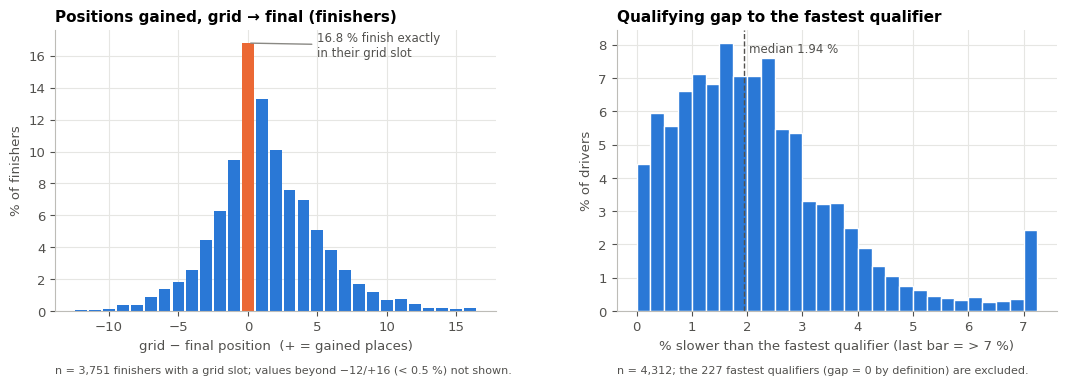

Exactly 0 positions gained: 16.8% | exactly 0 on lap 1: 28.6% | gaps exactly 0 (structural): 227 = one per race


In [6]:
# Figure W2_01 — distribution, redesigned (no KDE, % axes, zeros explained)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
pg = fin["positions_gained"].astype(int).value_counts(normalize=True).sort_index() * 100
pg = pg.loc[-12:16]
a1.bar(pg.index, pg.values, color=[ORANGE if v == 0 else BLUE for v in pg.index], width=0.85)
a1.annotate(f"{pg.loc[0]:.1f} % finish exactly\nin their grid slot", xy=(0, pg.loc[0]), xytext=(5, pg.loc[0] * 0.95),
            color=INK2, fontsize=8.5, arrowprops=dict(arrowstyle="-", color=GREY))
a1.set(title="Positions gained, grid → final (finishers)", xlabel="grid − final position  (+ = gained places)",
       ylabel="% of finishers")
a1.text(0.0, -0.22, f"n = {len(fin):,} finishers with a grid slot; values beyond −12/+16 (< 0.5 %) not shown.",
        transform=a1.transAxes, fontsize=8, color=INK2)

qg = at.loc[at["quali_gap_pct"] > 0, "quali_gap_pct"]        # the fastest qualifier of each race (gap = 0) is excluded
w = np.ones(len(qg)) * 100 / len(qg)
a2.hist(qg.clip(upper=7.01), bins=np.arange(0, 7.26, 0.25), weights=w, color=BLUE, edgecolor="white")
a2.axvline(qg.median(), color=INK2, ls="--", lw=1)
a2.text(qg.median() + 0.1, a2.get_ylim()[1] * 0.92, f"median {qg.median():.2f} %", color=INK2, fontsize=8.5)
a2.set(title="Qualifying gap to the fastest qualifier", xlabel="% slower than the fastest qualifier (last bar = > 7 %)",
       ylabel="% of drivers")
a2.text(0.0, -0.22, f"n = {len(qg):,}; the {int((at['quali_gap_pct'] == 0).sum())} fastest qualifiers (gap = 0 by definition) are excluded.",
        transform=a2.transAxes, fontsize=8, color=INK2)
save_fig(fig, "W2_01_distributions_redesigned")
print(f"Exactly 0 positions gained: {(fin['positions_gained'] == 0).mean():.1%} | exactly 0 on lap 1: "
      f"{(fin['gained_lap1'] == 0).mean():.1%} | gaps exactly 0 (structural): {(at['quali_gap_pct'] == 0).sum()} = one per race")

**Observation.** Once the structural zeros are removed, the qualifying gap starts at small positive values and has its
median just under 2 % (most of the field qualifies within 1–3 % of the fastest car). The positions-gained bars show a single
mode at 0 (about one finisher in six ends in the grid slot) and a longer right tail. That tail is partly mechanical: finishers
move up when cars ahead retire.

**What the figure does not show.** Gains among finishers ignore the 17 % of starters who did not finish, so this distribution
is not "what happens to a starter".

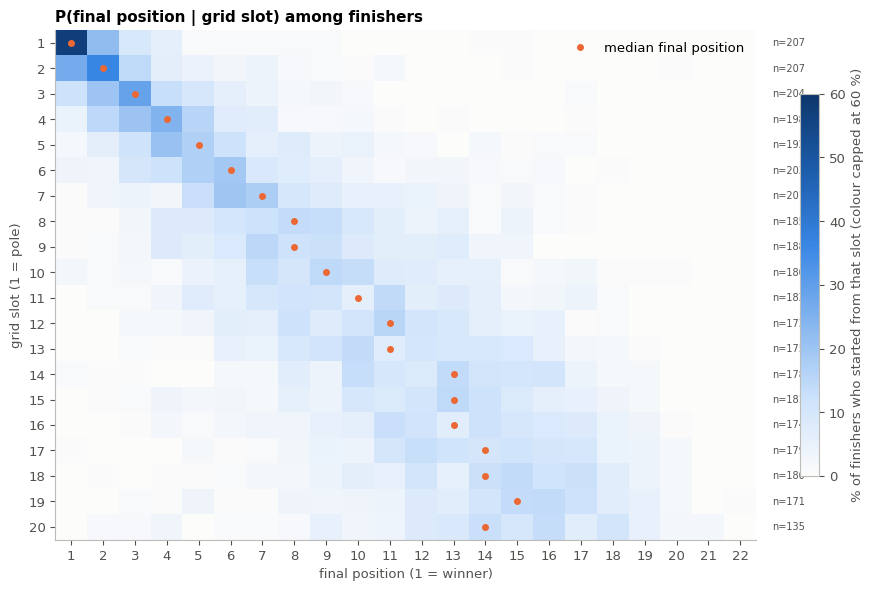

,n finishers,median final,P(final = grid slot),P(top 10)
grid,,,,
1.0,207,1.0,0.57,0.99
2.0,207,2.0,0.36,0.97
3.0,204,3.0,0.29,0.99
5.0,192,5.0,0.17,0.92
8.0,185,8.0,0.14,0.78
10.0,180,9.0,0.13,0.67
12.0,173,11.0,0.10,0.48
15.0,181,13.0,0.08,0.30
18.0,180,14.0,0.07,0.17


In [7]:
# Figure W2_02 — relationship: conditional distribution of the final position given the grid slot
g20 = fin[fin["grid"] <= 20]
cond = pd.crosstab(g20["grid"].astype(int), g20["final_pos"], normalize="index") * 100
n_row = g20.groupby("grid").size()
med = g20.groupby("grid")["final_pos"].median()
fig, ax = plt.subplots(figsize=(9.5, 6))
im = ax.imshow(cond.values, cmap=SEQ, aspect="auto", vmin=0, vmax=60,
               extent=[cond.columns.min() - .5, cond.columns.max() + .5, 20.5, .5])
ax.plot(med.values, med.index, "o", color=ORANGE, ms=4, label="median final position")
for gslot, n in n_row.items():
    ax.text(cond.columns.max() + 1, gslot, f"n={n}", va="center", fontsize=7, color=INK2)
ax.set(title="P(final position | grid slot) among finishers", xlabel="final position (1 = winner)",
       ylabel="grid slot (1 = pole)", yticks=range(1, 21), xticks=range(1, int(cond.columns.max()) + 1))
ax.grid(False); ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, shrink=.75, label="% of finishers who started from that slot (colour capped at 60 %)")
save_fig(fig, "W2_02_final_given_grid")
show = pd.DataFrame({"n finishers": n_row, "median final": med,
                     "P(final = grid slot)": [cond.loc[gs, gs] / 100 if gs in cond.columns else 0 for gs in cond.index],
                     "P(top 10)": g20.groupby("grid")["top10"].mean()}).loc[[1, 2, 3, 5, 8, 10, 12, 15, 18, 20]]
show.round(2)

**Observation.** Each row is one grid slot and sums to 100 %. From pole, 57 % of finishers win; the spread widens quickly
behind P3, and from the midfield the final position is spread over about ten places. The median final position (orange) follows
the diagonal at the front, but for the back of the grid it is **better than the starting slot** (P15 → 13th, P20 → 14th among
finishers), partly because cars ahead retire. This is the concrete meaning of IDC ≈ 0.8: the order is largely kept, with a spread of a few places.

**What it does not show.** This figure does not say that a car moved from P8 to P3 *would* finish where P3 starters do. The
drivers on each row differ in car, driver and reliability (part 2.5).

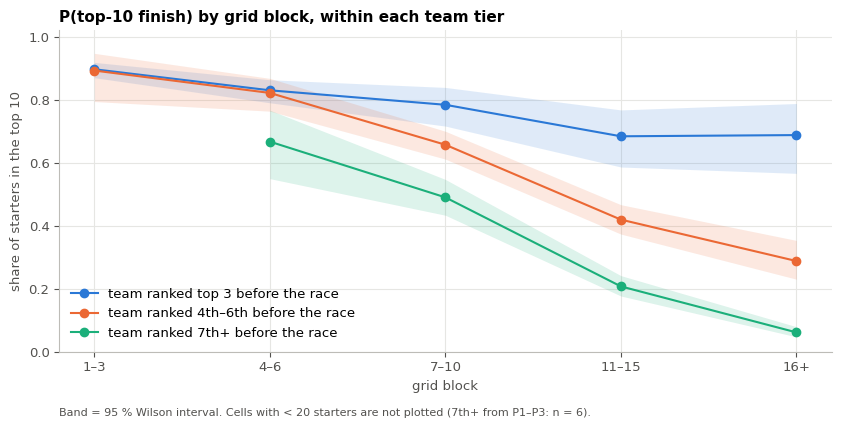

block,1–3,4–6,7–10,11–15,16+
tier,,,,,
4th–6th,0.89,0.82,0.66,0.42,0.29
7th+,1.00,0.67,0.49,0.21,0.06
top 3,0.90,0.83,0.78,0.68,0.69


In [8]:
# Figure W2_03 — segment view: P(top 10 | grid block) within each team tier (all starters with a slot and a team rank)
blocks = ["1–3", "4–6", "7–10", "11–15", "16+"]
seg = at[at["grid"].notna() & at["team_tier"].notna()]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
tab = []
for tier, col in zip(["top 3", "4th–6th", "7th+"], [BLUE, ORANGE, AQUA]):
    g = seg[seg["team_tier"] == tier].groupby("grid_block")["top10"].agg(["sum", "size"]).reindex(blocks)
    ok = g["size"] >= 20                                         # blocks with < 20 starters are not plotted
    p = g["sum"] / g["size"]; lo, hi = wilson(g["sum"], g["size"])
    x = np.arange(len(blocks))
    ax.plot(x[ok], p[ok], "o-", color=col, label=f"team ranked {tier} before the race")
    ax.fill_between(x[ok], lo[ok], hi[ok], color=col, alpha=.15, lw=0)
    tab.append(pd.DataFrame({"tier": tier, "block": blocks, "n": g["size"].values, "P(top 10)": p.values}))
ax.set_xticks(range(len(blocks)), blocks)
ax.set(title="P(top-10 finish) by grid block, within each team tier", xlabel="grid block", ylabel="share of starters in the top 10",
       ylim=(0, 1.02))
ax.legend(loc="lower left")
ax.text(0, -0.2, "Band = 95 % Wilson interval. Cells with < 20 starters are not plotted (7th+ from P1–P3: n = 6).",
        transform=ax.transAxes, fontsize=8, color=INK2)
save_fig(fig, "W2_03_top10_by_block_within_tier")
pd.concat(tab).pivot(index="tier", columns="block", values="P(top 10)").reindex(columns=blocks).round(2)

**Observation.** Within each team tier, starting further back goes with a lower chance of scoring, and the lines differ
by tier at every block: a top-3 team that starts 11th–15th scores in about two of three cases, while a team ranked 7th or lower
that starts 16th or further back scores in about one of twenty.

**What it does not show.** Holding the tier fixed removes only part of the differences between drivers. Inside a tier the drivers
who start further back may also have slower cars that weekend, weaker drivers or more failures. The pattern is a conditional
**association**; it is not the effect of moving the same car back.

### 2.5 Association, not effect: what the partial correlation can and cannot say (feedback 1 and 2)
**Observation (part 2.2).** The pooled ρ(grid, final) of 0.77 becomes **0.50 (95 % CI 0.46–0.53)** among drivers whose team had
the same championship rank before the race. That is all the number says.

**Why it does not identify "the effect of the car" nor "the effect of the grid":**
1. **Common causes not measured.** Driver skill, upgrades during the season and the car's suitability to each circuit move both the
   grid and the result. The constructors' rank is a **coarse proxy** for the car (it ranks teams, not the two cars, and lags the season).
2. **Selection on finishing.** The IDC and the partial ρ use finishers only, but finishing itself depends on the grid
   (DNF 9 % from P1–P3 vs 21 % from P11+, part 2.3). Conditioning on a post-start outcome can distort the association.
3. **Penalties and the sprint grids.** For 30.2 % of the starters with both values the grid differs from the qualifying order (C1 quoted 29.6 % over all rows); penalties can fall on fast cars
   that then recover, so part of the association may be about who receives penalties (a hypothesis: penalty records are not
   in the data).
4. **No random assignment.** Nobody assigns grid slots at random, so no estimate here equals E[Y(1) − Y(0)] (class 10:
   predicting is not intervening).

**Revised reading.** *The agreement between grid and result is weaker among teams of similar pre-race strength, which is
consistent with car performance acting as a common cause; it does not measure how much of the result the car causes.*

In [9]:
idc_quali = race_rho(at[at["finished"]], x="quali_pos").median()
print(f"IDC with the grid (main): {race['rho'].median():.3f} | IDC with the qualifying position instead: {idc_quali:.3f} | "
      f"grid differs from qualifying in {at['grid_differs_quali'].sum() / (at['grid'].notna() & at['quali_pos'].notna()).sum():.1%} "
      f"of starters with both values")

IDC with the grid (main): 0.811 | IDC with the qualifying position instead: 0.836 | grid differs from qualifying in 30.2% of starters with both values


**Observation.** The qualifying order agrees slightly more with the finishing order than the grid does. C1 read this as
"qualifying pace is the lever". A plausible alternative is penalties: drivers moved back after qualifying (often fast cars with
engine or gearbox changes) recover places, which weakens the grid–result agreement but not the qualifying–result agreement.
This difference does not identify any lever the team can pull.

### 2.6 Monaco and the comparison of 19 circuits (feedback 4)
C1 flagged Monaco because its 95 % interval was entirely above the overall IDC. With **19 circuits** compared at once, about one
interval out of 19 is expected to exclude the overall value by chance alone. We therefore (a) test each circuit's races against
all other races (Mann–Whitney, two-sided), (b) correct the 19 p-values with **Holm** (family-wise error) and **Benjamini–Hochberg**
(false discovery rate), and (c) show bootstrap intervals widened to the family-wise level (Bonferroni, 1 − 0.05/19).

Overall IDC 0.811 | Kruskal–Wallis across 19 circuits: H = 20.8, p = 0.29
Circuits with unadjusted p < 0.05: 2 | after Holm: 0 | after BH: 0


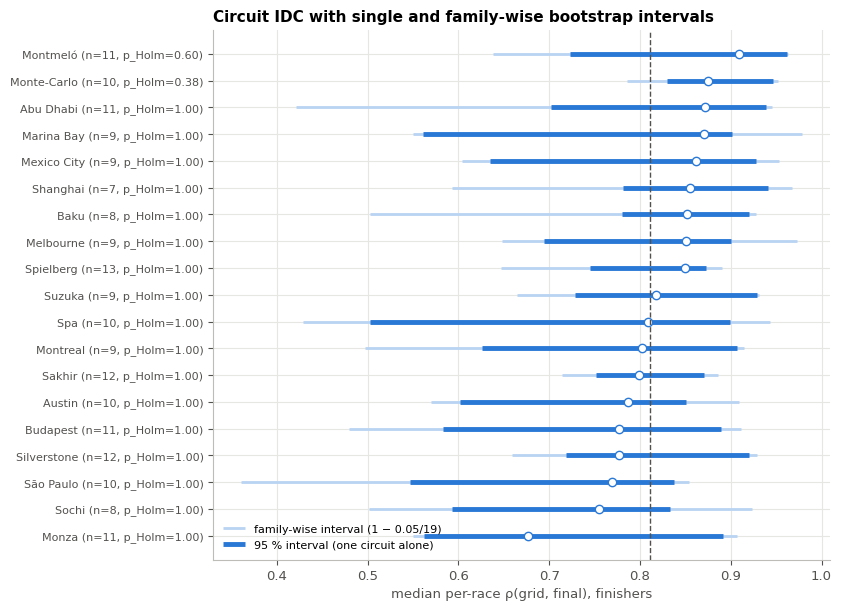

,races,IDC,CI95 low,CI95 high,family CI low,family CI high,p (vs other races),p Holm,p BH
circuit,,,,,,,,,
Monte-Carlo,10,0.875,0.830,0.947,0.785,0.953,0.020,0.377,0.319
Montmeló,11,0.909,0.723,0.961,0.638,0.963,0.034,0.605,0.319
Monza,11,0.676,0.562,0.892,0.550,0.907,0.274,1.000,0.702


In [10]:
def holm(p):
    p = np.asarray(p); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0
    for k, i in enumerate(order):
        run = max(run, (m - k) * p[i]); adj[i] = min(1, run)
    return adj

def bh(p):
    p = np.asarray(p); m = len(p); order = np.argsort(p); adj = np.empty(m); prev = 1
    for k in range(m - 1, -1, -1):
        i = order[k]; prev = min(prev, p[i] * m / (k + 1)); adj[i] = prev
    return adj

race_c = race.join(at.groupby("raceId")["circuit"].agg(lambda s: s.iloc[0]).rename("circ"))
n_by_circ = race_c.groupby("circ")["rho"].count()
circs = n_by_circ[n_by_circ >= 5].index
IDC_ALL = race_c["rho"].median()
alpha_fw = 0.05 / len(circs)
rows = []
for c in circs:
    r = race_c.loc[race_c["circ"] == c, "rho"].dropna().to_numpy()
    rest = race_c.loc[race_c["circ"] != c, "rho"].dropna().to_numpy()
    meds = np.median(RNG.choice(r, (5000, len(r))), axis=1)
    rows.append({"circuit": c, "races": len(r), "IDC": np.median(r),
                 "CI95 low": np.percentile(meds, 2.5), "CI95 high": np.percentile(meds, 97.5),
                 "family CI low": np.percentile(meds, 100 * alpha_fw / 2), "family CI high": np.percentile(meds, 100 * (1 - alpha_fw / 2)),
                 "p (vs other races)": stats.mannwhitneyu(r, rest, alternative="two-sided").pvalue})
circ = pd.DataFrame(rows).set_index("circuit")
circ["p Holm"], circ["p BH"] = holm(circ["p (vs other races)"]), bh(circ["p (vs other races)"])
circ = circ.sort_values("IDC")
kw = stats.kruskal(*[race_c.loc[race_c["circ"] == c, "rho"].dropna() for c in circs])
print(f"Overall IDC {IDC_ALL:.3f} | Kruskal–Wallis across {len(circs)} circuits: H = {kw.statistic:.1f}, p = {kw.pvalue:.2f}")
print(f"Circuits with unadjusted p < 0.05: {(circ['p (vs other races)'] < .05).sum()} | after Holm: {(circ['p Holm'] < .05).sum()} "
      f"| after BH: {(circ['p BH'] < .05).sum()}")

fig, ax = plt.subplots(figsize=(8.5, 6.2))
y = np.arange(len(circ))
ax.hlines(y, circ["family CI low"], circ["family CI high"], color="#b9d3f3", lw=2, label=f"family-wise interval (1 − 0.05/{len(circs)})")
ax.hlines(y, circ["CI95 low"], circ["CI95 high"], color=BLUE, lw=3.5, label="95 % interval (one circuit alone)")
ax.plot(circ["IDC"], y, "o", color="white", mec=BLUE, ms=6)
ax.axvline(IDC_ALL, color=INK2, ls="--", lw=1)
ax.set_yticks(y, [f"{c} (n={n}, p_Holm={p:.2f})" for c, n, p in zip(circ.index, circ["races"], circ["p Holm"])], fontsize=8)
ax.set(title="Circuit IDC with single and family-wise bootstrap intervals", xlabel="median per-race ρ(grid, final), finishers")
ax.legend(loc="lower left", fontsize=8)
save_fig(fig, "W2_05_circuits_multiplicity")
circ.loc[["Monte-Carlo", "Montmeló", "Monza"]].round(3)

**Observation.** Two circuits have an unadjusted p below 0.05: Monaco (p = 0.020, IDC above the average) and Montmeló
(p = 0.034). After correcting for 19 comparisons **neither is significant** (Monaco: Holm p = 0.38, BH p = 0.32), and the
Kruskal–Wallis test across circuits remains non-significant (p = 0.29). Monaco's single 95 % interval (0.83–0.95) excludes the
overall IDC, but its family-wise interval (0.79–0.95) **includes** it. With 10 races, the tails of a bootstrapped median are also
coarse, so the interval itself is approximate.

**Revised conclusion.** C1 said "only Monaco is clearly above the average". W2 says: *no circuit is distinguishable from the
overall IDC once the 19 comparisons are accounted for; Monaco has the highest agreement in point estimate, which is consistent with a
track where overtaking is hard, but the data do not establish that starting position "matters more" there.*

### 2.7 The first-lap share of position changes (feedback 5)
C1 reported that 40.4 % of all position changes among finishers happen on lap 1. That number compared **net** changes between
three snapshots (grid → end of lap 1 → finish). Every change that is later reversed, for example a pit-stop cycle in which a
driver loses and regains places, cancels out in the second snapshot. It therefore undercounts the race and **overstates** lap 1.
Here the changes are counted **lap by lap** from `lap_times` (248,124 laps), with the grid as "lap 0".

,lap-1 share of changes,how changes are counted
C1 method,0.404,"net, 3 snapshots (C1)"
W2 gross,0.099,lap by lap (gross)
W2 gross without own pit laps,0.131,"lap by lap, excluding the driver's own pit in/..."


Mean position change per driver: lap 1 = 1.78 places | later laps = 0.28 places per lap (6.5×) | own pit laps carry 37% of all gross changes


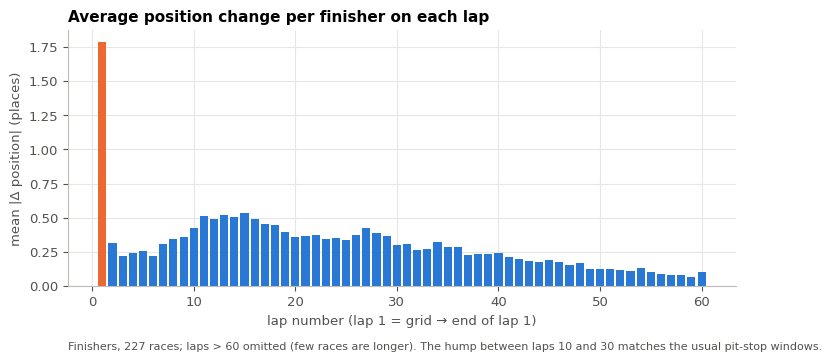

In [11]:
lt = lap_times[lap_times["raceId"].isin(at["raceId"])].sort_values(["raceId", "driverId", "lap"]).copy()
lt["prev_pos"] = lt.groupby(["raceId", "driverId"])["position"].shift()
lt = lt.merge(at[["raceId", "driverId", "grid"]], on=["raceId", "driverId"], how="left", validate="many_to_one")
lt.loc[lt["lap"] == 1, "prev_pos"] = lt.loc[lt["lap"] == 1, "grid"]          # lap 1 change = grid -> end of lap 1
lt["change"] = (lt["position"] - lt["prev_pos"]).abs()
own_pit = pd.concat([pit_stops[["raceId", "driverId", "lap"]], pit_stops[["raceId", "driverId", "lap"]].assign(lap=lambda d: d["lap"] + 1)])
lt = lt.merge(own_pit.drop_duplicates().assign(own_pit_lap=True), on=["raceId", "driverId", "lap"], how="left", validate="many_to_one")
lt["own_pit_lap"] = lt["own_pit_lap"].fillna(False).astype(bool)
assert lt.groupby(["raceId", "driverId"])["lap"].apply(lambda s: (s.diff().dropna() == 1).all()).all()   # no missing laps

m = fin.dropna(subset=["pos_lap1"])
ltf = lt.merge(m[["raceId", "driverId"]], on=["raceId", "driverId"])         # same population as C1: finishers
net1, net2 = (m["grid"] - m["pos_lap1"]).abs().sum(), (m["pos_lap1"] - m["final_pos"]).abs().sum()
def share(d): return d.loc[d["lap"] == 1, "change"].sum() / d["change"].sum()
lap1 = pd.DataFrame({
    "lap-1 share of changes": [net1 / (net1 + net2), share(ltf), share(ltf[~ltf["own_pit_lap"]])],
    "how changes are counted": ["net, 3 snapshots (C1)", "lap by lap (gross)", "lap by lap, excluding the driver's own pit in/out laps"]},
    index=["C1 method", "W2 gross", "W2 gross without own pit laps"])
display(lap1.round(3))
per_lap = ltf.groupby("lap")["change"].mean()
print(f"Mean position change per driver: lap 1 = {per_lap.loc[1]:.2f} places | later laps = "
      f"{ltf.loc[ltf['lap'] > 1, 'change'].mean():.2f} places per lap ({per_lap.loc[1] / ltf.loc[ltf['lap'] > 1, 'change'].mean():.1f}×) | "
      f"own pit laps carry {ltf.loc[ltf['own_pit_lap'], 'change'].sum() / ltf['change'].sum():.0%} of all gross changes")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
pl = per_lap.loc[:60]
ax.bar(pl.index, pl.values, color=[ORANGE if l == 1 else BLUE for l in pl.index], width=0.8)
ax.set(title="Average position change per finisher on each lap", xlabel="lap number (lap 1 = grid → end of lap 1)",
       ylabel="mean |Δ position| (places)")
ax.text(0, -0.25, f"Finishers, 227 races; laps > 60 omitted (few races are longer). The hump between laps 10 and 30 matches the usual pit-stop windows.",
        transform=ax.transAxes, fontsize=8, color=INK2)
save_fig(fig, "W2_04_position_changes_per_lap")

**Observation.** Lap 1 is by far the most **intense** lap: about 1.8 places per finisher against about 0.3 on a later lap
(roughly six times more). But it is not where "40 % of the changes" happen. Counted lap by lap, lap 1 holds about **10 %** of all
position changes, or **13 %** if we exclude the driver's own pit-stop laps. The C1 figure of 40.4 % is an **upper bound**
produced by the net-snapshot method.

**Revised conclusion.** C1: "40 % of position changes happen on lap 1; the start is almost half of the race." W2: *lap 1
concentrates the most position changes of any single lap, but between 10 % and 40 % of all changes depending on how a change is
counted; we report the lap-by-lap figure and keep 40.4 % only as the net upper bound.* Some lap-1 changes are also incidents
rather than overtakes, which the data cannot separate (no safety-car or incident data).

## 3. Data validation
The analytic table was validated in C1 with `assert` statements, which stop the notebook when they fail but print nothing when
they pass. In W2 every check is **executed and reported**: what was checked, how many rows, how many violations, and the action
taken (corrected, retained with justification, or flagged as a limitation).

### 3.1 Data dictionary (important variables)
`available at` refers to the decision timeline of part 5.1: **T0** = before qualifying (setup is fixed), **T1** = grid published,
before the start, **T2** = during the race, **T3** = after the chequered flag.

In [12]:
# Two variables are added in W2 (part 3.3): circuit_prior_races (replaces circuit_races for any predictive use)
# and starters_in_race (denominator for the grid range check)
at = at.sort_values(["date", "final_pos"]).reset_index(drop=True)
race_order = at.groupby("raceId")[["circuit", "date"]].first().sort_values("date")
race_order["circuit_prior_races"] = race_order.groupby("circuit").cumcount()      # races at the circuit BEFORE this one
at = at.merge(race_order[["circuit_prior_races"]], left_on="raceId", right_index=True, how="left", validate="many_to_one")
at["starters_in_race"] = at.groupby("raceId")["driverId"].transform("size")

DICT = [  # column, expected type, acceptable values / constraint, meaning of a missing value, available at, role
 ("raceId", "int", "id in races.csv, 2014–2024", "never missing", "T0", "key"),
 ("driverId", "int", "id in drivers.csv", "never missing", "T0", "key"),
 ("year", "int", "2014–2024", "never missing", "T0", "context / split variable"),
 ("date", "datetime", "inside the season; rounds in date order", "never missing", "T0", "split variable"),
 ("circuit", "string", "32 circuits", "never missing", "T0", "context"),
 ("circuit_races", "int", "1–13 (counts ALL 2014–2024 races)", "never missing", "uses future seasons", "C1 only; NOT a predictor"),
 ("circuit_prior_races", "int", "0–12 (races at the circuit before this one)", "never missing", "T0", "context (W2)"),
 ("era", "string", "2014–2021 / 2022–2024", "never missing", "T0", "context"),
 ("sprint_weekend", "bool", "True/False", "never missing", "T0", "context"),
 ("team", "string", "12 lineages", "never missing", "T0", "context"),
 ("constructor_rank_prev", "float", "1–11, team rank after the previous round", "team with no previous standings (4 rows)", "T0", "control"),
 ("team_tier", "string", "top 3 / 4th–6th / 7th+", "as constructor_rank_prev", "T0", "control"),
 ("quali_pos", "float", "1–24", "no qualifying record (16 rows)", "T1", "predictor (T1)"),
 ("quali_gap_pct", "float", "≥ 0; > 7 % flagged", "no time set (67 rows)", "T1", "predictor (T1)"),
 ("grid", "float", "1..starters in the race", "pit-lane start (77 rows)", "T1", "main explanatory variable"),
 ("pitlane_start", "bool", "True ⇔ grid missing", "never missing", "T1", "predictor (T1)"),
 ("starters_in_race", "int", "18–22", "never missing", "T1", "denominator"),
 ("pos_lap1", "float", "1..starters", "did not complete lap 1", "T2", "after the start: NOT a predictor"),
 ("race_pace_gap_pct", "float", "≥ 0", "retired before half distance", "T2", "after the start: NOT a predictor"),
 ("final_pos", "int", "complete ranking 1..n in each race", "never missing", "T3", "outcome Y (ordinal)"),
 ("position", "float", "1..n", "not classified (retired < 90 % distance)", "T3", "outcome (official)"),
 ("positions_gained", "float", "grid − final_pos", "pit-lane start", "T3", "built from Y: NOT a predictor"),
 ("finished", "bool", "status Finished or +n Laps", "never missing", "T3", "outcome"),
 ("classified", "bool", "position not missing", "never missing", "T3", "outcome"),
 ("status", "string", "139 raw statuses", "never missing", "T3", "outcome"),
 ("top10", "bool", "exactly 10 True per race", "never missing", "T3", "outcome Y (future model)"),
 ("points", "float", "> 0 ⇔ top10", "never missing", "T3", "built from Y: NOT a predictor"),
]
ddict = pd.DataFrame(DICT, columns=["column", "expected type", "acceptable values", "missing means", "available at", "role"])
ddict["% missing"] = [round(100 * at[c].isna().mean(), 1) for c in ddict["column"]]
ddict.to_csv(PROC / "w2_data_dictionary.csv", index=False)
ddict

,column,expected type,acceptable values,missing means,available at,role,% missing
0,raceId,int,"id in races.csv, 2014–2024",never missing,T0,key,0.0
1,driverId,int,id in drivers.csv,never missing,T0,key,0.0
2,year,int,2014–2024,never missing,T0,context / split variable,0.0
3,date,datetime,inside the season; rounds in date order,never missing,T0,split variable,0.0
4,circuit,string,32 circuits,never missing,T0,context,0.0
5,circuit_races,int,1–13 (counts ALL 2014–2024 races),never missing,uses future seasons,C1 only; NOT a predictor,0.0
6,circuit_prior_races,int,0–12 (races at the circuit before this one),never missing,T0,context (W2),0.0
7,era,string,2014–2021 / 2022–2024,never missing,T0,context,0.0
8,sprint_weekend,bool,True/False,never missing,T0,context,0.0
9,team,string,12 lineages,never missing,T0,context,0.0


### 3.2 Executable checks
Each check returns the number of rows (or races) checked and the number of violations. A check that finds violations does
not stop the notebook: it shows the rows and records the action.

In [13]:
LOG = []
def check(cid, name, rule, checked, bad, action, unit="rows"):
    """Record one validation check. `bad` is a boolean mask (or a count) of violations."""
    nbad = int(bad.sum()) if hasattr(bad, "sum") else int(bad)
    LOG.append({"id": cid, "check": name, "rule": rule, "checked": f"{checked:,} {unit}", "violations": nbad,
                "result": "pass" if nbad == 0 else "flag", "action": action})
    return nbad

TYPE_OK = {"int": pd.api.types.is_integer_dtype, "float": pd.api.types.is_float_dtype, "bool": pd.api.types.is_bool_dtype,
           "string": pd.api.types.is_string_dtype, "datetime": pd.api.types.is_datetime64_any_dtype}
per_race = at.groupby("raceId")
n_races = at["raceId"].nunique()

check("C01", "Unique key", "(raceId, driverId) appears once", len(at), at.duplicated(["raceId", "driverId"]), "none needed")
check("C02", "Types", "each dictionary column has its expected type", len(ddict),
      sum(not TYPE_OK[t](at[c]) for c, t in zip(ddict["column"], ddict["expected type"])), "none needed", "columns")
check("C03", "Missing identifiers", "raceId, driverId, constructorId, circuitId, driver, team not missing", len(at),
      at[["raceId", "driverId", "constructorId", "circuitId", "driver", "team"]].isna().any(axis=1), "none needed")
raw_keys = set(map(tuple, results_raw.loc[results_raw["raceId"].isin(period_ids - not_raced), ["raceId", "driverId"]].to_numpy()))
check("C04", "Raw → analytic reconciliation", "keys of raw results 2014–2024 (minus Belgium 2021) = keys of the table", len(at),
      len(raw_keys ^ set(map(tuple, at[["raceId", "driverId"]].to_numpy()))), "none needed")
check("C05", "Grid range", "1 ≤ grid ≤ starters in the race; grid missing ⇔ pit-lane start", len(at),
      (at["grid"].notna() & ~at["grid"].between(1, at["starters_in_race"])) | (at["grid"].isna() != at["pitlane_start"]), "none needed")
check("C06", "Final order", "final_pos is exactly 1..n in every race", n_races,
      (~per_race["final_pos"].apply(lambda s: sorted(s) == list(range(1, len(s) + 1)))), "none needed", "races")
check("C07", "Race-level counts", "one winner, one pole sitter and exactly ten top-10 finishers per race", n_races,
      (per_race["win"].sum() != 1) | (per_race["grid"].apply(lambda s: (s == 1).sum()) != 1) | (per_race["top10"].sum() != 10),
      "none needed", "races")
check("C08", "Category consistency", "finished ⇒ classified; end_cause = 'finished' ⇔ finished", len(at),
      (at["finished"] & ~at["classified"]) | ((at["end_cause"] == "finished") != at["finished"]),
      "retained: running at the flag but < 90 % of the distance is correctly 'not classified'; kept as finisher (C1 definition)")
c08 = (at["finished"] & ~at["classified"])
check("C09", "Points rule", "top10 ⇔ points > 0 (2014–2024: points only for positions 1–10)", len(at),
      at["top10"] != (at["points"] > 0), "none needed")
anom = at["top10"] & ~at["finished"]
check("C10", "Status anomaly", "a driver in the points should have a finishing status", len(at), anom,
      "retained; flagged (flag_status_anomaly); finisher-only KPIs exclude it")
dates = per_race[["year", "round", "date"]].first().sort_values(["year", "round"])
check("C11", "Date logic", "race date in its season; rounds in date order; no date after 2024", n_races,
      (dates["date"].dt.year != dates["year"]) | (dates.groupby("year")["date"].diff().dt.days <= 0) | (dates["date"] > "2024-12-31"),
      "none needed", "races")
check("C12", "Laps and lap-1 position", "laps ≤ race distance; 1 ≤ pos_lap1 ≤ starters", len(at),
      (at["laps"] > per_race["laps"].transform("max")) | (at["pos_lap1"].notna() & ~at["pos_lap1"].between(1, at["starters_in_race"])),
      "none needed")
check("C13", "Plausible qualifying gap", "0 ≤ quali_gap_pct ≤ 7 % (107 % rule)", int(at["quali_gap_pct"].notna().sum()),
      at["quali_gap_pct"] > 7, "retained and flagged (quali_outlier): real slow laps or wet sessions, not errors")
cs = cstand.merge(races_raw[["raceId", "year", "round"]], on="raceId", how="left", validate="many_to_one")
prev_std = cs.assign(round=cs["round"] + 1)[["year", "round", "constructorId", "position"]].rename(columns={"position": "std_prev"})
chk = at[at["round"] > 1].merge(prev_std, on=["year", "round", "constructorId"], how="left", validate="many_to_one")
check("C14", "Linked-table consistency", "constructor_rank_prev = raw standings after the previous round (rounds > 1)",
      int(chk["std_prev"].notna().sum()), (chk["std_prev"].notna() & (chk["std_prev"] != chk["constructor_rank_prev"])),
      "none needed (confirms no same-race information)")
check("C15", "Join coverage", "share of rows matched in each join (qualifying, lap 1, team rank)", len(at),
      at["quali_pos"].isna() | at["constructor_rank_prev"].isna(),
      "retained: structural gaps (no time set; new team); not imputed in the table")

checks = pd.DataFrame(LOG)
checks.to_csv(PROC / "w2_validation_checks.csv", index=False)
print(f"{len(checks)} checks | pass: {(checks['result'] == 'pass').sum()} | flagged: {(checks['result'] == 'flag').sum()}")
display(checks)
display(at.loc[anom | c08, ["year", "name", "driver", "status", "finished", "classified", "final_pos", "position", "points", "laps"]]
        .assign(race_laps=lambda d: d.index.map(lambda i: per_race["laps"].max()[at.loc[i, "raceId"]])))
cov = pd.Series({"qualifying record": at["quali_pos"].notna().mean(), "position after lap 1": at["pos_lap1"].notna().mean(),
                 "team rank before the race": at["constructor_rank_prev"].notna().mean()}, name="join coverage")
cov.map("{:.1%}".format).to_frame()

15 checks | pass: 11 | flagged: 4


,id,check,rule,checked,violations,result,action
0,C01,Unique key,"(raceId, driverId) appears once","4,606 rows",0,pass,none needed
1,C02,Types,each dictionary column has its expected type,27 columns,0,pass,none needed
2,C03,Missing identifiers,"raceId, driverId, constructorId, circuitId, dr...","4,606 rows",0,pass,none needed
3,C04,Raw → analytic reconciliation,keys of raw results 2014–2024 (minus Belgium 2...,"4,606 rows",0,pass,none needed
4,C05,Grid range,1 ≤ grid ≤ starters in the race; grid missing ...,"4,606 rows",0,pass,none needed
5,C06,Final order,final_pos is exactly 1..n in every race,227 races,0,pass,none needed
6,C07,Race-level counts,"one winner, one pole sitter and exactly ten to...",227 races,0,pass,none needed
7,C08,Category consistency,finished ⇒ classified; end_cause = 'finished' ...,"4,606 rows",1,flag,retained: running at the flag but < 90 % of th...
8,C09,Points rule,top10 ⇔ points > 0 (2014–2024: points only for...,"4,606 rows",0,pass,none needed
9,C10,Status anomaly,a driver in the points should have a finishing...,"4,606 rows",1,flag,retained; flagged (flag_status_anomaly); finis...


,year,name,driver,status,finished,classified,final_pos,position,points,laps,race_laps
13,2014,Australian Grand Prix,Jules Bianchi,+8 Laps,True,False,14,NaN,0.0,49,57
613,2015,Belgian Grand Prix,Valtteri Bottas,Power Unit,False,True,9,9.0,2.0,43,43


,join coverage
qualifying record,99.7%
position after lap 1,97.0%
team rank before the race,99.9%


**Observation.** Eleven of the fifteen checks pass with zero violations. Four are flagged, and all four rows or groups are kept on purpose:
- **C08.** The rule "finished ⇒ classified" has one exception: Bianchi, Australia 2014, took the flag 8 laps down (49 of 57 laps,
  under 90 % of the distance), so he is correctly **not classified**. Our first rule was too strict, not the data. The row stays
  a finisher under the C1 definition ("took the chequered flag").
- **C10.** One driver (Bottas, Belgium 2015) is classified 9th and scored points, but the raw status reads "Power Unit". The
  official position and points agree with each other, so the row is kept. Because it is not a "finisher", it is outside the
  finisher-only KPIs; it is marked with `flag_status_anomaly`.
- **C13.** 105 qualifying gaps above 7 % are kept and flagged. They are real slow laps (problems, wet sessions), not typing errors.
- **C15** reports the join coverage (19 rows lack a qualifying record or a team rank). These gaps are structural (no qualifying time, a new team) and are not imputed in the table.

**Assumption.** The Ergast data are correct where they agree with each other. We cannot check them against an external official
source in this notebook.

### 3.3 Treatments and row counts (nothing dropped silently)
C1 transformations are reproduced from `cleaning_log.csv`, and the W2 changes are added with rows before and after. W2 **adds
columns and flags; it removes no rows**. KPI subsets (for example, finishers only) are documented as analysis populations, not
as deletions.

In [14]:
at["flag_status_anomaly"] = anom
c1_log = pd.read_csv(PROC / "cleaning_log.csv")
w2_steps = pd.DataFrame([
    {"step": "W2-1. circuit_prior_races", "rule": "races at the circuit BEFORE each race (replaces circuit_races for prediction)",
     "rows before": len(at), "rows after": len(at), "evidence": "part 5.2, risk R4"},
    {"step": "W2-2. starters_in_race", "rule": "number of starters per race (denominator for range checks)",
     "rows before": len(at), "rows after": len(at), "evidence": "check C05"},
    {"step": "W2-3. flag_status_anomaly", "rule": "flag the classified-in-points row with a failure status (1 row)",
     "rows before": len(at), "rows after": len(at), "evidence": "check C10"},
    {"step": "KPI population (not a deletion)", "rule": "IDC and ρ use finishers with a grid slot",
     "rows before": len(at), "rows after": len(fin), "evidence": "part 2.0; 855 rows kept in the table"},
])
treat = pd.concat([c1_log.assign(stage="C1"), w2_steps.assign(stage="W2")], ignore_index=True)
assert len(at) == 4606 and at[["raceId", "driverId"]].duplicated().sum() == 0
at.to_csv(PROC / "analytic_driver_race_2014_2024_w2.csv", index=False)
print(f"Updated analytic table saved: {len(at):,} rows x {at.shape[1]} columns (C1 table: 4,606 x 42)")
treat[["stage", "step", "rule", "rows before", "rows after", "evidence"]]

Updated analytic table saved: 4,606 rows x 45 columns (C1 table: 4,606 x 42)


,stage,step,rule,rows before,rows after,evidence
0,C1,1. Period,Keep seasons 2014–2024 (master filter on races...,26759,4626,"Notebook 01, parts 3–4"
1,C1,2. Not-raced races,Exclude races with < 5 laps in lap_times,4626,4606,Belgium 2021: 1 lap behind the safety car
2,C1,3. Pit-lane starts,grid = 0 -> grid NaN + pitlane_start flag (kep...,4606,4606,"Notebook 01, part 5"
3,C1,4. Qualifying join,"results -> qualifying, one-to-one; times parse...",4606,4606,validate='one_to_one'
4,C1,5. Race pace,"Median lap excl. lap 1, in/out laps and laps >...",4606,4606,Section 6
5,C1,6. Team strength,Constructor rank after previous round; round 1...,4606,4606,Avoids leakage
6,C1,7. Team lineage,20 constructor ids -> 12 lineages,4606,4606,W1 A.5
7,W2,W2-1. circuit_prior_races,races at the circuit BEFORE each race (replace...,4606,4606,"part 5.2, risk R4"
8,W2,W2-2. starters_in_race,number of starters per race (denominator for r...,4606,4606,check C05
9,W2,W2-3. flag_status_anomaly,flag the classified-in-points row with a failu...,4606,4606,check C10


## 4. Sampling and representativeness
### 4.1 Target, observed and analytical populations
| Level | Definition | How records got there |
|---|---|---|
| **Target population** | Driver-starts in the Grands Prix where the strategist will use the evidence: the **current and next seasons** (2025 onwards, including the **2026 technical regulations**). | Not observed: these races are in the future or outside the data. |
| **Observed population** | Every championship Grand Prix of 2014–2024 recorded by Ergast and published on Kaggle (228 races, 4,626 driver-race results). | Not a probability sample. It is a **census of the past period** chosen by us (W1/C1: one engine formula, one points scale, complete tables). |
| **Analytical dataset** | 227 races and 4,606 driver-race rows (Belgium 2021 excluded); the IDC uses 3,751 finishers with a grid slot. | Deterministic rules from notebook 02 and part 2.0. |

"We have all the rows" does not mean "we have the population": every row describes the **past**, while the decision is about
**future** races (class 6: all available records ≠ the population relevant for future decisions).

In [15]:
print(f"Last race in the data: {at['date'].max():%Y-%m-%d} | rows from 2025 or later: {(at['year'] >= 2025).sum()}")
idc_era = race.groupby("era")["rho"].agg(["median", "count"])
part_era = {e: partial_spearman(g["grid"], g["final_pos"], g["constructor_rank_prev"]) for e, g in pdat.groupby("era")}
idc_all_starters = race_rho(at[at["grid"].notna()]).median()
circ_n = at.groupby("circuit")["raceId"].nunique()
bias = pd.DataFrame([
    ("B1 Time / regime coverage", "IDC by era", ", ".join(f"{e}: {v:.3f} ({int(n)} races)" for e, (v, n) in idc_era.iterrows()),
     "partial ρ by era: " + ", ".join(f"{e}: {v:.2f}" for e, v in part_era.items()) + "; 0 races from 2025–2026"),
    ("B2 Selection on finishing", "IDC finishers vs all starters", f"{IDC_ALL:.3f} vs {idc_all_starters:.3f}",
     "DNF 9.0 % from P1–P3 vs 21.1 % from P11+ (part 2.3): who is 'observed at the finish' depends on the grid"),
    ("B3 Calendar composition", "circuits with < 5 races", f"{(circ_n < 5).sum()} circuits, {circ_n[circ_n < 5].sum()} races",
     "excluded from circuit-level KPIs; 2020 calendar (pandemic) added one-off tracks"),
], columns=["bias", "measure", "value", "evidence"])
bias

Last race in the data: 2024-12-08 | rows from 2025 or later: 0


,bias,measure,value,evidence
0,B1 Time / regime coverage,IDC by era,"2014–2021: 0.818 (159 races), 2022–2024: 0.797...","partial ρ by era: 2014–2021: 0.47, 2022–2024: ..."
1,B2 Selection on finishing,IDC finishers vs all starters,0.811 vs 0.654,DNF 9.0 % from P1–P3 vs 21.1 % from P11+ (part...
2,B3 Calendar composition,circuits with < 5 races,"13 circuits, 38 races",excluded from circuit-level KPIs; 2020 calenda...


**Plausible sources of sampling or coverage bias.**
1. **B1 · Time and regulation coverage.** The data stop in 2024, before the 2026 regulations. Within the data, the association
   already moves between eras (the partial ρ is higher in 2022–2024). Any conclusion is about the 2014–2024 regime, and its
   transfer to future seasons is an **assumption**.
2. **B2 · Selection on finishing.** The IDC is measured on finishers. Retirements are more frequent from the back of the grid, so
   the finisher population is not a random part of the starters. Including retirements lowers the agreement from 0.81 to 0.65.
3. **B3 · Calendar composition.** Circuits enter and leave the calendar. Thirteen circuits with fewer than five races are
   absent from the circuit KPIs, and the per-circuit samples are small (7–13 races).

A fourth limitation is about **measurement**, not selection: weather, safety cars, tyres and setups are not recorded.

### 4.2 Reproducible subsample (25 % of races, stratified by season)
The KPI is computed per **race**, and the drivers of one race are not independent, so we sample **whole races** (cluster sampling),
25 % of the races of each season (stratified by season so every year is represented). For contrast we also take a
**convenience sample**: the first 25 % of races in time (as a careless `head()` of the file would give).

,complete dataset,random 25 % (seed 2026),convenience: first 25 % in time,random − complete,convenience − complete
races,227.000,57.000,57.000,-170.000,-170.000
driver-race rows,4606.000,1160.000,1203.000,-3446.000,-3403.000
IDC (median per-race ρ),0.811,0.821,0.811,0.010,0.000
P(top 10 | grid 1–3),0.897,0.912,0.901,0.015,0.004
segment: share of starts by top-3 teams,0.296,0.295,0.284,-0.001,-0.011
segment: DNF rate,0.174,0.190,0.200,0.016,0.026
segment: share of races in 2022–2024,0.300,0.316,0.000,0.016,-0.300


IDC over 1,000 stratified 25 % subsamples: mean 0.812, SD (≈ standard error) 0.021, middle 95 % 0.777–0.855


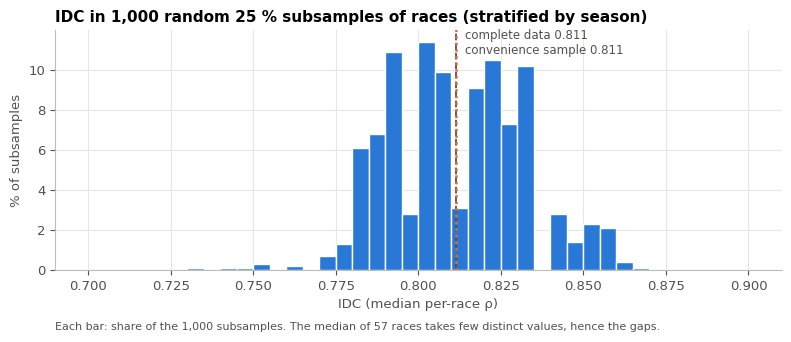

In [16]:
def subsample_races(rng, frac=0.25):
    """25 % of the races of each season (rounded), drawn without replacement."""
    ids = []
    for y, g in race.groupby("year"):
        ids += list(rng.choice(g.index.to_numpy(), size=int(round(frac * len(g))), replace=False))
    return np.array(ids)

def profile(ids):
    d = at[at["raceId"].isin(ids)]
    starters = d[d["grid"].notna()]
    return pd.Series({
        "races": len(ids), "driver-race rows": len(d),
        "IDC (median per-race ρ)": race.loc[ids, "rho"].median(),
        "P(top 10 | grid 1–3)": starters.loc[starters["grid"] <= 3, "top10"].mean(),
        "segment: share of starts by top-3 teams": (d["team_tier"] == "top 3").mean(),
        "segment: DNF rate": 1 - d["finished"].mean(),
        "segment: share of races in 2022–2024": (race.loc[ids, "era"] == "2022–2024").mean()})

sample_ids = subsample_races(np.random.default_rng(SEED))
conv_ids = race.sort_values("date").index[: int(round(0.25 * len(race)))].to_numpy()
comp = pd.DataFrame({"complete dataset": profile(race.index.to_numpy()), "random 25 % (seed 2026)": profile(sample_ids),
                     "convenience: first 25 % in time": profile(conv_ids)})
comp["random − complete"] = comp["random 25 % (seed 2026)"] - comp["complete dataset"]
comp["convenience − complete"] = comp["convenience: first 25 % in time"] - comp["complete dataset"]
pd.DataFrame({"raceId": sample_ids}).to_csv(PROC / "w2_subsample_race_ids.csv", index=False)
display(comp.round(3))

# Sampling variability: repeat the same design 1,000 times with seeds 2026, 2027, ...
reps = np.array([race.loc[subsample_races(np.random.default_rng(SEED + b)), "rho"].median() for b in range(1000)])
print(f"IDC over 1,000 stratified 25 % subsamples: mean {reps.mean():.3f}, SD (≈ standard error) {reps.std(ddof=1):.3f}, "
      f"middle 95 % {np.percentile(reps, 2.5):.3f}–{np.percentile(reps, 97.5):.3f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(reps, bins=np.arange(0.70, 0.90, 0.005), weights=np.ones(len(reps)) * 100 / len(reps), color=BLUE, edgecolor="white")
conv_idc = comp.loc["IDC (median per-race ρ)", "convenience: first 25 % in time"]
ax.axvline(IDC_ALL, color=INK2, ls="--", lw=1.3)
ax.axvline(conv_idc, color=ORANGE, ls=":", lw=1.8)
ax.text(IDC_ALL + 0.003, ax.get_ylim()[1] * 0.9, f"complete data {IDC_ALL:.3f}\nconvenience sample {conv_idc:.3f}", color=INK2, fontsize=8.5)
ax.text(0, -0.25, "Each bar: share of the 1,000 subsamples. The median of 57 races takes few distinct values, hence the gaps.",
        transform=ax.transAxes, fontsize=8, color=INK2)
ax.set(title="IDC in 1,000 random 25 % subsamples of races (stratified by season)", xlabel="IDC (median per-race ρ)",
       ylabel="% of subsamples")
save_fig(fig, "W2_06_subsample_idc")

**Observation.**
- **Random 25 % (57 races, 1,160 rows).** IDC 0.821 vs 0.811 in the complete data (+0.010), which is well inside the sampling
  variability measured by the 1,000 repetitions (SD 0.021; middle 95 % 0.78–0.86). The segment shares are also close: starts by
  top-3 teams 29.5 % vs 29.6 %, races in 2022–2024 31.6 % vs 30.0 %, DNF rate 19.0 % vs 17.4 %.
- **Convenience sample (first 57 races in time = 2014–2016).** Its IDC happens to equal the complete value (0.811), but its
  composition is biased: **0 %** of its races are from 2022–2024 (vs 30 %) and its DNF rate is 20.0 % (vs 17.4 %).
- **Lesson.** A matching KPI does not prove a sample is representative. The convenience sample matches by chance on one number
  and misses an entire regulation era by design. The difference between the two samples comes from **how** they were drawn
  (sampling bias), not from chance, and drawing more races the same way would not remove it.

### 4.3 Why a train/test split does not show that the data represent the target population
A train/test split divides **the same observed rows** into two parts. If the observed data do not contain something that matters
for the target population (2025–2026 races, the 2026 regulations, new circuits, rain information), then **neither** part contains it.
A good result on the test part would only show that the pattern holds inside 2014–2024. It would not show that it holds in
the seasons the strategist cares about. Representativeness depends on how the data were collected (part 4.1), and the split
cannot repair that (class 6: "a train/test split does not fix a biased source").

## 5. Leakage audit
### 5.1 When is the decision made, and what is known then?
| Moment | Event | What is known | Use |
|---|---|---|---|
| **T0** | Before qualifying. Under parc fermé the car setup is **fixed from qualifying onwards** | calendar, circuit, team rank after the previous round, history | the strategist's setup decision |
| **T1** | Qualifying and penalties done, grid published, before the start | + qualifying position and gap, **grid**, pit-lane start | the legitimate moment for a top-10 prediction |
| **T2** | During the race | + lap-1 position, lap times, pit stops, race pace | not available for a pre-race decision |
| **T3** | After the flag | final position, status, points, top 10 (**Y**) | outcome only |

**Key consequence (feedback 3).** At T0, when the setup is chosen, the grid does **not exist yet**. The data contain no setup
variable. Our evidence can describe what outcomes are associated with each grid slot (an input for the strategist), but it
cannot say which setup to choose. A future model at T1 can use the grid; a T0 use can only treat the grid as a **scenario**
("if we qualify around P8, what share of similar cars scored?"), not as an observed fact.

In [17]:
AVAIL = dict(zip(ddict["column"], ddict["available at"]))
AVAIL.update({"gained_lap1": "T2", "fastest_lap_rank": "T2", "end_cause": "T3", "podium": "T3", "win": "T3", "laps": "T3",
              "grid_block": "T1", "quali_outlier": "T1", "grid_differs_quali": "T1", "quali_best_s": "T1", "team": "T0"})
FEATURES_T0 = ["constructor_rank_prev", "team_tier", "circuit", "circuit_prior_races", "era", "sprint_weekend"]
FEATURES_T1 = FEATURES_T0 + ["grid", "pitlane_start", "quali_pos", "quali_gap_pct", "grid_differs_quali"]
TARGET = "top10"
assert all(AVAIL[c] == "T0" for c in FEATURES_T0) and all(AVAIL[c] in ("T0", "T1") for c in FEATURES_T1)
assert "circuit_races" not in FEATURES_T1 and TARGET not in FEATURES_T1
avail = pd.Series(AVAIL, name="available at").to_frame()
avail["allowed in a T1 model"] = avail.index.isin(FEATURES_T1)
avail.sort_values("available at").groupby("available at").apply(lambda d: ", ".join(d.index)).to_frame("columns")

,columns
available at,
T0,"raceId, driverId, year, date, circuit, circuit..."
T1,"quali_outlier, grid_block, grid_differs_quali,..."
T2,"fastest_lap_rank, gained_lap1, race_pace_gap_p..."
T3,"classified, status, top10, positions_gained, p..."
uses future seasons,circuit_races


### 5.2 Context-specific leakage risks, with evidence from the dataset

In [18]:
rank_same = cs[["year", "round", "constructorId", "position"]].rename(columns={"position": "rank_after_same_race"})
f_same = fin.merge(rank_same, on=["year", "round", "constructorId"], how="left", validate="many_to_one").dropna(
    subset=["rank_after_same_race", "constructor_rank_prev"])
rho_same = stats.spearmanr(f_same["final_pos"], f_same["rank_after_same_race"])[0]
rho_prev = stats.spearmanr(f_same["final_pos"], f_same["constructor_rank_prev"])[0]
rho_lap1 = stats.spearmanr(fin.dropna(subset=["pos_lap1"])["pos_lap1"], fin.dropna(subset=["pos_lap1"])["final_pos"])[0]
rho_pace = stats.spearmanr(fin.dropna(subset=["race_pace_gap_pct"])["race_pace_gap_pct"], fin.dropna(subset=["race_pace_gap_pct"])["final_pos"])[0]
rho_grid = stats.spearmanr(fin["grid"], fin["final_pos"])[0]
mon14 = at[(at["circuit"] == "Monte-Carlo") & (at["year"] == 2014)].iloc[0]
raw_dup = results_raw.duplicated(["raceId", "driverId"])
dev_median = at.loc[at["year"] <= 2022, "quali_gap_pct"].median()
rows_per_driver = at.groupby("driverId").size()
risks = pd.DataFrame([
 ("R1 Target-derived variables", "present → excluded",
  f"top10 = (points > 0) in {(at['top10'] == (at['points'] > 0)).mean():.0%} of rows; positions_gained = grid − final_pos exactly; "
  f"status/finished describe the end of the race",
  "a model would 'predict' Y from a copy of Y (perfect but useless)",
  "never in the feature lists (assert in 5.1); listed as T3 in the dictionary"),
 ("R2 In-race information (T2)", "present → excluded",
  f"ρ(final, lap-1 position) = {rho_lap1:.2f} and ρ(final, race pace) = {rho_pace:.2f}, both above ρ(final, grid) = {rho_grid:.2f}",
  "inflated performance; unusable before the start", "pos_lap1, gained_lap1, race_pace_gap_pct, fastest_lap_rank excluded"),
 ("R3 Linked table: standings after the same race", "absent in the table (present in raw data)",
  f"ρ(final, team rank after the SAME race) = {rho_same:.2f} vs after the PREVIOUS round = {rho_prev:.2f}; check C14: 0 mismatches",
  "the same-race rank already contains the result", "join on round − 1 (C1), verified in C14"),
 ("R4 Future aggregate: circuit_races", "present → replaced",
  f"Monaco 2014 has circuit_races = {mon14['circuit_races']} although it is the first race there (circuit_prior_races = {mon14['circuit_prior_races']})",
  "uses the number of races that happen after the prediction", "circuit_prior_races computed from earlier races only (part 3.3)"),
 ("R5 Repeated entities / dependent rows", "present → handled by the split design",
  f"exactly 10 top-10 finishers in each of {n_races} races; quali_gap_pct is normalised by the race's fastest time; "
  f"{at['driverId'].nunique()} drivers, median {rows_per_driver.median():.0f} rows each",
  "a row-level random split puts part of a race in train and part in test (they share the race's outcome and normalisation)",
  "split by whole races and by season (part 6)"),
 ("R6 Duplicated records", "absent",
  f"0 duplicated keys in the table; raw duplicates = {int(raw_dup.sum())}, all from 1950–1978 "
  f"({int(raw_dup[results_raw['raceId'].isin(period_ids)].sum())} in 2014–2024)",
  "none", "check C01 keeps watching it"),
 ("R7 Preprocessing / choices learned on the full data", "uncertain",
  f"median quali_gap_pct: all seasons {at['quali_gap_pct'].median():.2f} % vs 2014–2022 only {dev_median:.2f} %; C1 thresholds "
  f"(period, < 5 laps, 7 %, ≥ 5 races, tiers) were chosen after exploring all seasons",
  "imputing or scaling with all rows passes test information to training", "fixed domain rules documented; learned values fit on training only (part 6.3)"),
 ("R8 Temporal drift", "present → chronological validation",
  "partial ρ " + ", ".join(f"{e}: {v:.2f}" for e, v in part_era.items()) + f"; IDC 2023 = {race.loc[race['year'] == 2023, 'rho'].median():.2f}",
  "random CV mixes regimes and is optimistic for future seasons", "train on past seasons, validate and test on later ones"),
], columns=["risk", "status", "evidence (this dataset)", "potential consequence", "mitigation"])
risks.to_csv(PROC / "w2_leakage_audit.csv", index=False)
risks

,risk,status,evidence (this dataset),potential consequence,mitigation
0,R1 Target-derived variables,present → excluded,top10 = (points > 0) in 100% of rows; position...,a model would 'predict' Y from a copy of Y (pe...,never in the feature lists (assert in 5.1); li...
1,R2 In-race information (T2),present → excluded,"ρ(final, lap-1 position) = 0.79 and ρ(final, r...",inflated performance; unusable before the start,"pos_lap1, gained_lap1, race_pace_gap_pct, fast..."
2,R3 Linked table: standings after the same race,absent in the table (present in raw data),"ρ(final, team rank after the SAME race) = 0.80...",the same-race rank already contains the result,"join on round − 1 (C1), verified in C14"
3,R4 Future aggregate: circuit_races,present → replaced,Monaco 2014 has circuit_races = 10 although it...,uses the number of races that happen after the...,circuit_prior_races computed from earlier race...
4,R5 Repeated entities / dependent rows,present → handled by the split design,exactly 10 top-10 finishers in each of 227 rac...,a row-level random split puts part of a race i...,split by whole races and by season (part 6)
5,R6 Duplicated records,absent,0 duplicated keys in the table; raw duplicates...,none,check C01 keeps watching it
6,R7 Preprocessing / choices learned on the full...,uncertain,median quali_gap_pct: all seasons 1.85 % vs 20...,imputing or scaling with all rows passes test ...,fixed domain rules documented; learned values ...
7,R8 Temporal drift,present → chronological validation,"partial ρ 2014–2021: 0.47, 2022–2024: 0.55; ID...",random CV mixes regimes and is optimistic for ...,"train on past seasons, validate and test on la..."


**Observation.** Eight risks were checked. Five are **present** in the data and are neutralised by design (R1, R2 and R4 by
exclusion or replacement; R5 and R8 by the split design). One is present only in the raw tables and is already avoided (R3). Duplicates
are absent (R6). One stays **uncertain** (R7): C1 chose its cleaning thresholds after seeing all seasons, including the future
test seasons. Those rules are domain-based (for example the 107 % rule), and we will not change them now, but the test set is not
fully "untouched" (part 6.5).

### 5.3 Is a future predictive use legitimate?
**Yes, at T1, with the T1 feature list.** Predicting a top-10 finish after the grid is published uses only information that exists at
that moment, and the "you finish where you start" baseline from C1 remains the reference. **No, for the setup decision as worded
in C1.** No setup is recorded, and the grid is not known when the setup is fixed. The C1 recommendation by circuit is therefore
**withdrawn** (feedback 3). The project gives the strategist an input (the value associated with a grid slot), not a setup rule.

## 6. Train / validation / test design
### 6.1 Choice of split and why
| Option | Verdict for this project |
|---|---|
| Random 80/20 by row | **Rejected.** It splits races (R5): the ten top-10 places of one race would be shared between train and test. It also mixes past and future (R8). |
| Stratified by `top10` | **Unnecessary.** The prevalence is fixed by construction (exactly 10 per race, about 49 % of rows), so any split by whole races keeps it. |
| Grouped by race (random races) | Better, but a random set of races still lets 2024 races train a rule tested on 2016. |
| **Chronological by season** ✔ | **Chosen.** It matches the business process (the strategist uses the past to decide on the **next** races), keeps every race whole (grouping comes for free), and exposes the 2022 regulation change (R8). |

**Design.** *Development* = seasons 2014–2022; *test* = seasons 2023–2024 (about 20 % of the rows). Inside development,
**expanding-window validation by season**: train on all seasons before year *v* and validate on *v*, for *v* = 2018 … 2022.
The test seasons are used only once, at the end of a future modelling stage. In W2 nothing is fitted on them, and they are only
counted, checked for overlap, and passed through a preprocessing step that was fitted on development data.

In [19]:
DEV_YEARS, TEST_YEARS = range(2014, 2023), range(2023, 2025)
at["split"] = np.where(at["year"].isin(TEST_YEARS), "test", "development")
dev, test = at[at["split"] == "development"].copy(), at[at["split"] == "test"].copy()

def describe_subset(d):
    return pd.Series({"seasons": f"{d['year'].min()}–{d['year'].max()}", "races": d["raceId"].nunique(), "rows": len(d),
                      "share of rows": len(d) / len(at), "top-10 prevalence": d["top10"].mean(),
                      "races in 2022–2024 era": (d.groupby("raceId")["era"].first() == "2022–2024").mean(),
                      "finishers with grid slot": int((d["finished"] & d["grid"].notna()).sum()),
                      "quali_gap_pct missing": int(d["quali_gap_pct"].isna().sum())})
split_tab = pd.DataFrame({"development": describe_subset(dev), "test": describe_subset(test), "total": describe_subset(at)})
display(split_tab)

# Overlap and integrity checks (each must be True)
overlap = pd.Series({
    "no race in both subsets": len(set(dev["raceId"]) & set(test["raceId"])) == 0,
    "no (race, driver) key in both subsets": len(set(map(tuple, dev[["raceId", "driverId"]].to_numpy())) &
                                                 set(map(tuple, test[["raceId", "driverId"]].to_numpy()))) == 0,
    "seasons do not overlap": len(set(dev["year"]) & set(test["year"])) == 0,
    "every development race is earlier than every test race": dev["date"].max() < test["date"].min(),
    "development + test = all rows (none lost)": len(dev) + len(test) == len(at),
}, name="passed")
display(overlap.to_frame())
assert overlap.all()
at[["raceId", "driverId", "year", "split"]].to_csv(PROC / "w2_split_assignment.csv", index=False)

# Entities that appear in test but not in development: legitimate (they are known at T1), reported for transparency
new_drivers = sorted(set(test["driver"]) - set(dev["driver"]))
new_circuits = sorted(set(test["circuit"]) - set(dev["circuit"]))
print(f"Drivers in test never seen in development: {len(new_drivers)} ({', '.join(new_drivers)}) — "
      f"{test['driver'].isin(new_drivers).sum()} test rows")
print(f"Circuits in test never seen in development: {new_circuits} — {test['circuit'].isin(new_circuits).sum()} test rows | "
      f"team lineages new in test: {len(set(test['team']) - set(dev['team']))}")

,development,test,total
seasons,2014–2022,2023–2024,2014–2024
races,181,46,227
rows,3687,919,4606
share of rows,0.800478,0.199522,1.0
top-10 prevalence,0.490914,0.500544,0.492835
races in 2022–2024 era,0.121547,1.0,0.299559
finishers with grid slot,2974,777,3751
quali_gap_pct missing,58,9,67


,passed
no race in both subsets,True
"no (race, driver) key in both subsets",True
seasons do not overlap,True
every development race is earlier than every test race,True
development + test = all rows (none lost),True


Drivers in test never seen in development: 6 (Franco Colapinto, Jack Doohan, Liam Lawson, Logan Sargeant, Oliver Bearman, Oscar Piastri) — 106 test rows
Circuits in test never seen in development: ['Las Vegas'] — 40 test rows | team lineages new in test: 0


**Observation.** Development holds 181 races (3,687 rows) and test 46 races (919 rows, 20.0 %). The top-10 prevalence
is about 49–50 % in both, as expected from the 10-per-race rule. All five overlap checks pass. Six drivers and one circuit
(Las Vegas, first held in 2023) appear only in the test seasons. They are not leakage: in a real deployment, new drivers and
circuits do appear, and the preprocessing must handle them (part 6.3). All test races are under the 2022 regulations, while
development has only one season (2022) of that era. That is the regime shift the strategist faces too, and it is a stated
limitation.

### 6.2 Validation plan inside development (no test data involved)

In [20]:
VAL_YEARS = range(2018, 2023)
folds = []
for v in VAL_YEARS:
    tr_idx = dev.index[dev["year"] < v]
    va_idx = dev.index[dev["year"] == v]
    assert set(at.loc[tr_idx, "year"]).isdisjoint(TEST_YEARS) and set(at.loc[va_idx, "year"]).isdisjoint(TEST_YEARS)
    assert len(set(at.loc[tr_idx, "raceId"]) & set(at.loc[va_idx, "raceId"])) == 0
    assert at.loc[tr_idx, "date"].max() < at.loc[va_idx, "date"].min()
    folds.append((v, tr_idx, va_idx))
fold_tab = pd.DataFrame([{"fold": f"validate {v}", "train seasons": f"2014–{v - 1}",
                          "train races": at.loc[tr, "raceId"].nunique(), "train rows": len(tr),
                          "validation races": at.loc[va, "raceId"].nunique(), "validation rows": len(va),
                          "top-10 prevalence (train / validation)": f"{at.loc[tr, 'top10'].mean():.3f} / {at.loc[va, 'top10'].mean():.3f}",
                          "test rows used": 0} for v, tr, va in folds]).set_index("fold")
fold_tab

,train seasons,train races,train rows,validation races,validation rows,top-10 prevalence (train / validation),test rows used
fold,,,,,,,
validate 2018,2014–2017,79,1647,21,420,0.480 / 0.500,0
validate 2019,2014–2018,100,2067,21,420,0.484 / 0.500,0
validate 2020,2014–2019,121,2487,17,340,0.487 / 0.500,0
validate 2021,2014–2020,138,2827,21,420,0.488 / 0.500,0
validate 2022,2014–2021,159,3247,22,440,0.490 / 0.500,0


**Observation.** Five chronological folds, each validating one season with all earlier seasons as training. Every fold
passed three assertions (no test season, no shared race, training strictly earlier than validation). The last fold (validate 2022)
is the first season of the new regulations, so the validation plan already measures how a rule learned in one regime behaves in
the next. Specifications (features, imputation, model type, threshold) would be chosen **only** from these folds.

### 6.3 Preprocessing learned from training data only
Two operations learn parameters from data:
- a **median imputer** for the two pre-race numeric variables with gaps (`quali_gap_pct`: no time set; `constructor_rank_prev`: new team);
- a **one-hot encoder** for `circuit`, with `handle_unknown="ignore"` so a circuit never seen in training becomes a row of zeros
  instead of an error or a new learned category.

They are fitted on the development data and then **applied** to test without refitting. Inside the validation plan, the same
transformer is cloned and refitted in each fold on that fold's training seasons only.

In [21]:
NUM, CAT = ["quali_gap_pct", "constructor_rank_prev"], ["circuit"]
prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
prep.fit(dev[NUM + CAT])                                         # <- learns ONLY from development seasons
learned = prep.named_transformers_["num"].statistics_.copy()
known_circuits = list(prep.named_transformers_["cat"].categories_[0])

X_test = prep.transform(test[NUM + CAT])                         # <- applies the learned rule, no refit
assert np.array_equal(learned, prep.named_transformers_["num"].statistics_)          # parameters unchanged by transform
assert list(prep.named_transformers_["cat"].categories_[0]) == known_circuits

print(pd.DataFrame({"learned on development (used)": learned,
                    "if fitted on ALL rows (leaky, not used)": at[NUM].median().to_numpy()}, index=NUM).round(3))
lv = test["circuit"].isin(new_circuits).to_numpy()
cat_block = X_test[:, len(NUM):]
print(f"\nCircuits learned: {len(known_circuits)} | test rows at unseen circuits: {lv.sum()} -> circuit columns all zero: "
      f"{bool((cat_block[lv] == 0).all())}")
print(f"Test rows with quali_gap_pct missing: {test['quali_gap_pct'].isna().sum()} -> filled with the development median "
      f"{learned[0]:.3f} (not with any test statistic)")

# Same transformer inside the validation plan: cloned and refitted per fold on that fold's training seasons only
per_fold = []
for v, tr, va in folds:
    p = clone(prep).fit(at.loc[tr, NUM + CAT])
    seen = set(p.named_transformers_["cat"].categories_[0])
    per_fold.append({"fold": f"validate {v}", "median quali_gap_pct learned": p.named_transformers_["num"].statistics_[0],
                     "circuits learned": len(seen),
                     "validation rows at circuits unseen in that fold's training": int((~at.loc[va, "circuit"].isin(seen)).sum())})
pd.DataFrame(per_fold).set_index("fold").round(3)

                       learned on development (used)  \
quali_gap_pct                                  2.037   
constructor_rank_prev                          6.000   

                       if fitted on ALL rows (leaky, not used)  
quali_gap_pct                                            1.846  
constructor_rank_prev                                    6.000  

Circuits learned: 31 | test rows at unseen circuits: 40 -> circuit columns all zero: True
Test rows with quali_gap_pct missing: 9 -> filled with the development median 2.037 (not with any test statistic)


,median quali_gap_pct learned,circuits learned,validation rows at circuits unseen in that fold's training
fold,,,
validate 2018,2.248,21,20
validate 2019,2.255,22,0
validate 2020,2.207,22,100
validate 2021,2.164,27,60
validate 2022,2.079,30,20


**Observation.** The imputer learned a median qualifying gap of 2.04 % from development, while the full data (with test)
would give 1.85 %. Using the full data would have passed test information into training, a small but real leak (risk R7). The
learned values stay identical after transforming test, so nothing was refitted. The 40 test rows at Las Vegas (2023 and 2024) are encoded as
"unknown circuit" (all zeros). Inside the folds the learned median changes from fold to fold, and four of the five validation
seasons contain circuits not seen in their training seasons (100 rows in 2020, the year of the one-off tracks). The test seasons
reproduce the same situation.

### 6.4 Descriptive robustness check of the KPI (not predictive accuracy)
Our main deliverable is a **descriptive** KPI, so the holdout seasons are also used once as an **independent robustness check**:
is the agreement between grid and result similar in the later seasons? This is not a measure of predictive accuracy, and no
choice is made from it.

In [22]:
def idc_ci(ids, B=2000, rng=np.random.default_rng(SEED)):
    v = race.loc[ids, "rho"].dropna().to_numpy()
    meds = np.median(rng.choice(v, (B, len(v))), axis=1)
    return pd.Series({"races": len(v), "IDC": np.median(v), "CI low": np.percentile(meds, 2.5), "CI high": np.percentile(meds, 97.5)})
robust = pd.DataFrame({"development 2014–2022": idc_ci(dev["raceId"].unique()), "test 2023–2024": idc_ci(test["raceId"].unique())}).T
robust["races"] = robust["races"].astype(int)
robust.round(3)

,races,IDC,CI low,CI high
development 2014–2022,181,0.811,0.789,0.842
test 2023–2024,46,0.812,0.741,0.868


**Observation.** The agreement between grid and result is of the same order in the holdout seasons as in development, with
overlapping intervals (see the table). The descriptive conclusion "grid and finishing order agree strongly" therefore holds in
the seasons kept apart.

### 6.5 Limits and treatment of the test information
- **The test seasons are not untouched.** C1 explored all 2014–2024 seasons (for example the IDC by season, which showed the low
  value of 2023, and the outlier list, which included Las Vegas 2023). The cleaning rules were also chosen with those seasons in view
  (risk R7). The holdout is therefore **independent of model fitting**, not independent of our eyes.
- **What we commit to.** From now on, the test seasons are not used to choose features, cleaning thresholds, the imputation, a
  model or a decision threshold. They are evaluated **once**, after the specification is frozen on the five validation folds.
- **What the test can and cannot show.** It can show whether a rule learned on 2014–2022 still works in 2023–2024. It cannot
  show that it works in 2025–2026 or under the 2026 regulations (part 4.3).
- **No model or metric in W2**, as the assignment specifies. The next stage fits the T1 classifier on the folds above.

## 7. Revised conclusions and management summary
### 7.1 What changed from C1
| C1 statement | Status | W2 statement | Evidence |
|---|---|---|---|
| "The starting position strongly **determines** the result" | **Revised** | Grid and finishing order **agree** strongly among finishers (IDC 0.811, 95 % CI 0.789–0.835); this is an association, not an effect of the grid. | Parts 2.1–2.2 |
| "A large part of it **is the car**" (0.77 → 0.50) | **Revised** | The association is weaker among teams of equal pre-race rank (partial ρ 0.50), *consistent with* the car as a common cause; it does not measure the car's effect. | Part 2.5 |
| "Only **Monaco** is clearly above the average; lean the setup toward qualifying there" | **Withdrawn** | No circuit is distinguishable after correcting for 19 comparisons (Monaco Holm p = 0.38). | Part 2.6 |
| "**40 %** of position changes happen on lap 1; the start is almost half of the race" | **Revised** | Lap 1 is the most intense lap (about 6.5× a later lap), but it holds 10–13 % of all changes counted lap by lap; 40.4 % is a net-snapshot upper bound. | Part 2.7 |
| "Qualifying pace **is the lever**" (0.84 vs 0.81) | **Withdrawn** | The qualifying order agrees slightly more with the result than the grid; grid penalties are a plausible reason. No lever is identified. | Parts 2.5, 5.3 |
| "Each grid slot **lost costs** about 7 points of probability (P7–P14)" | **Revised** | Starters one slot further back scored about 7 pp less often; this compares different drivers, not the same car moved back. | Parts 2.3, 2.4 |
| "Setup recommendation by circuit" | **Withdrawn** | The setup is fixed before the grid exists and is not recorded; the evidence is an input, not a setup rule. | Part 5.1, 5.3 |
| "The 2022 rules did not make the start less decisive" | **Kept, reworded** | The IDC is similar in 2014–2021 and 2022–2024 (0.82 vs 0.80); a before/after comparison cannot attribute it to the rules. | Part 4.1 |

### 7.2 Observations, assumptions and managerial recommendations
**Observations.**
- In a typical 2014–2024 race the finishing order of the finishers closely follows the grid: IDC 0.81, and a finisher ends about
  2.8 places from the grid slot.
- The association is weaker, but still clearly positive, among teams of the same pre-race strength (0.50).
- Circuit differences and the "Monaco effect" do not survive a correction for multiple comparisons.
- Lap 1 is the single most intense lap, but most position changes happen later in the race.
- The data pass 11 of 15 validation checks outright. The other four are explained and kept.

**Assumptions.**
- The constructors' championship rank before the race is an adequate (coarse) proxy for car strength.
- Patterns from 2014–2024 are relevant to future seasons. This is untested for the 2026 regulations.
- Ergast records are correct where they are internally consistent.

**Managerial recommendations (to the strategist).**
- Treat the grid–result tables as **planning inputs** (what finishing outcomes usually go with each grid slot for a team of a
  given strength), not as a promise of what a better grid would cause.
- Do not rank circuits by "how much qualifying matters" with this data. The differences are within noise.
- Before relying on any predictive tool, wait for the validated T1 model and for evidence from post-2024 seasons.

### 7.3 Management summary
Since C1 we corrected how the evidence is read, not the data. The grid and the finishing order agree strongly in 2014–2024 (IDC
0.81): a finisher typically ends about three places from the starting slot. This is an association. It does not show that a
better grid causes a better result, and holding team strength fixed lowers it to 0.50 without measuring the car's effect. Two C1
claims did not survive: Monaco is not distinguishable once 19 circuits are compared, and lap 1 holds 10–13 % of all position
changes, not 40 %, although it is the most intense lap. The recommendation on car setup is withdrawn because setups are not
recorded and the grid is unknown when the setup is fixed. Fifteen validation checks found no errors that change a KPI. The data
cover only past seasons, so transfer to the 2026 rules is uncertain. Next step: fit the top-10 classifier on the five
chronological folds and evaluate it once on 2023–2024.

### 7.4 Next analytical step
Fit the T1 top-10 classifier (logistic regression, then a tree-based model) with the T1 feature list and the preprocessing of
part 6.3 inside a pipeline. Compare it with the "you finish where you start" baseline on the five chronological folds (AUC, log
loss, calibration), freeze the specification, and evaluate it **once** on 2023–2024.

## 8. AI-use disclosure
**Tool:** Claude (Anthropic), in Cowork mode. **Used for:** reading the W2 brief against our C1 submission and the instructor's
feedback, proposing the structure of this notebook, drafting code and text, and finding issues in C1 (the net-snapshot method
behind the 40.4 % figure, the structural zeros in the gap variables, the future information in `circuit_races`).
**Verification by the team:** the notebook was re-run from top to bottom (*Restart & Run All*), and every number quoted in the
text was checked against the printed outputs. The methodological choices (chronological split, the withdrawn conclusions, the
retained flagged rows) were discussed and are defended by the team. All data are public; nothing confidential was uploaded.